# 학생 중도포기 예측 프로젝트: 전체 분석 기록
Team EduCare | Illini Data Science Club 프로젝트 · 첫 분석부터 후속 분석까지

**질문:** 학업을 중도에 포기할 가능성이 높은 학생을, 도움을 줄 수 있을 만큼 일찍 찾아낼 수 있는가?
**데이터:** UCI *Predict Students' Dropout and Academic Success* (포르투갈 한 대학, 학생 4,424명, 변수 36개). 이 중 1,421명(32.1%)이 중도포기한 데이터였습니다.

| 부분 | 한 일 | 결과 |
|---|---|---|
| Part 1 첫 분석 (2학기 정보 포함) | 8개 모델 비교, XGBoost 선택, SHAP으로 해석 | 최고 모델 정확도 88%, F1 0.81. 그러나 2학기 정보가 포함되어 실제 조기 경보에는 쓸 수 없는 점수로 판단했고, 이 한계를 다음 단계 과제로 남겼습니다 |
| Part 2 후속 분석 (1학기 말까지의 정보) | 2학기 정보 제외, 반복 교차 검증, SMOTE, 3분류 | ROC-AUC 약 0.91, F1 약 0.77. SMOTE는 이점이 없었고, 3분류 Macro F1은 약 0.69(재학 중 구분이 가장 어려움)였습니다 |
| Part 3 중도포기 학생 유형 (군집) | 중도포기 학생을 비슷한 특성끼리 묶고, 모델이 놓치는 유형 확인 | 4가지 유형(학기 중 이탈 32%, 채무·미납 18%, 장학금 9%, 학업 중간 40%)으로 나뉘었고, 장학금·학업 중간형은 예측에서 많이 놓치는 것으로 확인되었습니다 |
| Part 4 상담 인원이 정해졌을 때 | 위험 순서로 K%에게만 연락한다고 가정하고 단순 규칙과 비교 | 상위 20%에 연락하면 정밀도 약 92%, 중도포기 학생의 약 57%를 포착했습니다(단순 규칙은 정밀도 78%). 상위 30%는 정밀도 80%, 재현율 75%였습니다 |

### 참고 사항
- Part 1의 점수는 Part 2~4의 점수와 직접 비교할 수 없습니다. Part 1은 2학기 정보를 포함했고 데이터를 한 번만 나눠 평가했습니다. Part 2~4는 2학기 정보를 뺐고, 5조각 교차 검증을 2~3회 반복해 평균과 변동을 함께 보았습니다.
- 이 데이터에는 상담이나 지원을 한 기록이 없어서, 어떤 개입이 효과가 있는지는 판단할 수 없었습니다. 이 분석이 보여 주는 것은 예측이 얼마나 맞는지와 누구를 놓치는지입니다.

# Part 1. 첫 분석: 2학기 정보를 포함한 모델 비교

## 1-1. 문제 정의

**문제의 배경**

- 고등교육에서는 대략 3명 중 1명이 졸업하지 못하는 것으로 알려져 있으며, 개인과 사회 모두에 비용이 큰 문제입니다.
- 학생 개인에게 중도포기는 소득 기회의 상실, 학위 없이 남는 학자금 부채, 좁아진 진로 선택지로 이어질 수 있습니다.
- 학교 입장에서 높은 중도포기율은 학업 지원, 재정 지원, 학생 참여 측면에 공백이 있다는 신호로 볼 수 있습니다.

**연구 질문**

> *중도포기 위험이 있는 학생을, 개입할 수 있을 만큼 일찍(이상적으로는 1학기 전이나 1학기 중에) 찾아낼 수 있는가?*

**설계상 고려한 점**

이 데이터에는 1학기와 2학기 변수가 모두 들어 있었습니다. 하지만 실제 조기 경보 시스템이라면 *너무 늦기 전에* 위험 학생을 찾아야 한다고 보았습니다. 그래서 **어떤 변수를 어느 시점에 알 수 있는지**를 따져 보았고, 2학기 변수는 데이터 누수(data leakage, 예측 시점에는 알 수 없는 정보가 모델에 들어가는 문제)의 원인이 될 수 있다고 표시해 두었습니다.

**데이터 출처:** UCI Machine Learning Repository, *Predict Students' Dropout and Academic Success*
- 약 4,400건 | 변수 36개 | 다양한 전공과 학생 배경

In [24]:
# ── 환경 설정 ──────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import warnings
warnings.filterwarnings('ignore')

In [25]:
# ── 데이터 불러오기 ───────────────────────────────────────────────────────────
df = pd.read_csv("data.csv", sep=";")

print(f"Shape: {df.shape}")
print(f"Missing values: {df.isna().sum().sum()}")
df.head()

Shape: (4424, 37)
Missing values: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [26]:
# ── 변수 정리: 읽기 쉬운 라벨 붙이기 ──────────────────────────────────
course_map = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (Evening)"
}

df["Course_name"] = df["Course"].map(course_map)
df["Gender_label"] = df["Gender"].map({0: "Female", 1: "Male"})

# 이진 타깃: 1 = 중도포기, 0 = 중도포기하지 않음(졸업 또는 재학 중)
df["Target_Dropout"] = (df["Target"] == "Dropout").astype(int)

print("Target distribution:")
print(df["Target"].value_counts())
print(f"\nDropout rate: {df['Target_Dropout'].mean():.1%}")

Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Dropout rate: 32.1%


**결과 해석: 데이터 개요**

- 학생 4,424명, 변수 36개(+ 결과 라벨 1개)였고 결측치는 없는 것으로 확인되었습니다.
- 결과는 세 가지였습니다: 졸업(Graduate) 2,209명(약 50%), 중도포기(Dropout) 1,421명(32.1%), 재학 중(Enrolled) 794명(약 18%).
- 즉 학생 3명 중 1명이 중도포기한 상황을 다루는 프로젝트였습니다.

## 1-2. EDA: 데이터 탐색

데이터를 세 단계로 나누어 살펴보았고, 각 단계는 앞 단계의 결과를 바탕으로 진행했습니다.
1. **타깃 분포**: 클래스 불균형 확인
2. **학업 요인**: 성적과 이수 과목이 주된 요인인지 확인
3. **재정 및 인구통계 요인**: 학업 외에 추가로 설명력이 있는지 확인

각 그래프 아래에 해석을 붙였고, 이 해석을 이후 모델링 결정의 근거로 삼았습니다.

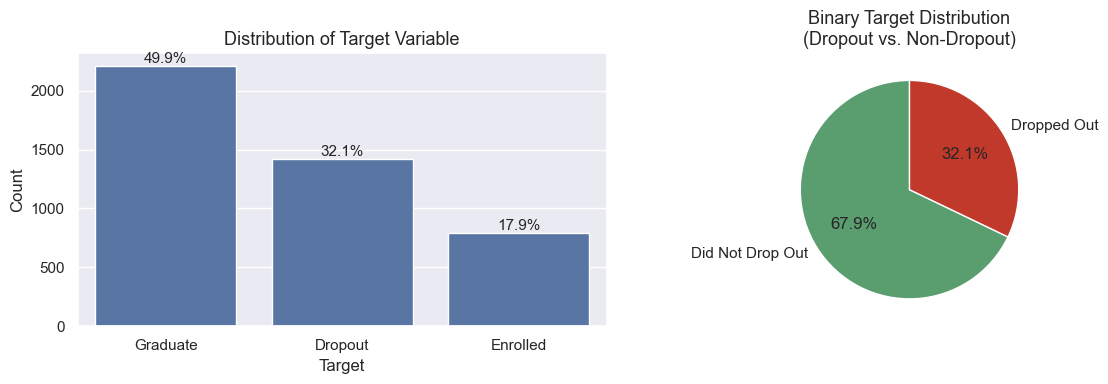

In [27]:
# ── EDA 1: 타깃 변수 분포 ───────────────────────────────────
# 졸업이 전체의 거의 50%를 차지한다.
# 중도포기(32%) vs 중도포기 아님(68%) → 클래스 불균형이 있다.
# 그래서 정확도만 보면 오해할 수 있어 F1 점수를 함께 본다.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 빈도 막대그래프
order = df["Target"].value_counts().index
sns.countplot(data=df, x="Target", order=order, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()/len(df)*100:.1f}%',
                     (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=11)
axes[0].set_title("Distribution of Target Variable", fontsize=13)
axes[0].set_ylabel("Count")

# 이진 분류 기준으로 보기
binary_counts = df["Target_Dropout"].value_counts()
axes[1].pie(binary_counts, labels=["Did Not Drop Out", "Dropped Out"],
            autopct='%1.1f%%', colors=["#5a9e6f", "#c0392b"], startangle=90)
axes[1].set_title("Binary Target Distribution\n(Dropout vs. Non-Dropout)", fontsize=13)

plt.tight_layout()
plt.show()

**결과 해석: 타깃 분포**

- 중도포기 비율은 32%, 나머지는 68%였습니다. 모델이 모든 학생을 "중도포기 아님"으로 답해도 정확도가 68%가 나오는 구조였습니다.
- 그래서 정확도(Accuracy)만으로는 모델 성능을 판단하기 어렵다고 보았고, 중도포기 학생을 얼마나 잘 찾아내는지를 함께 반영하는 F1 점수를 주요 지표로 정했습니다.

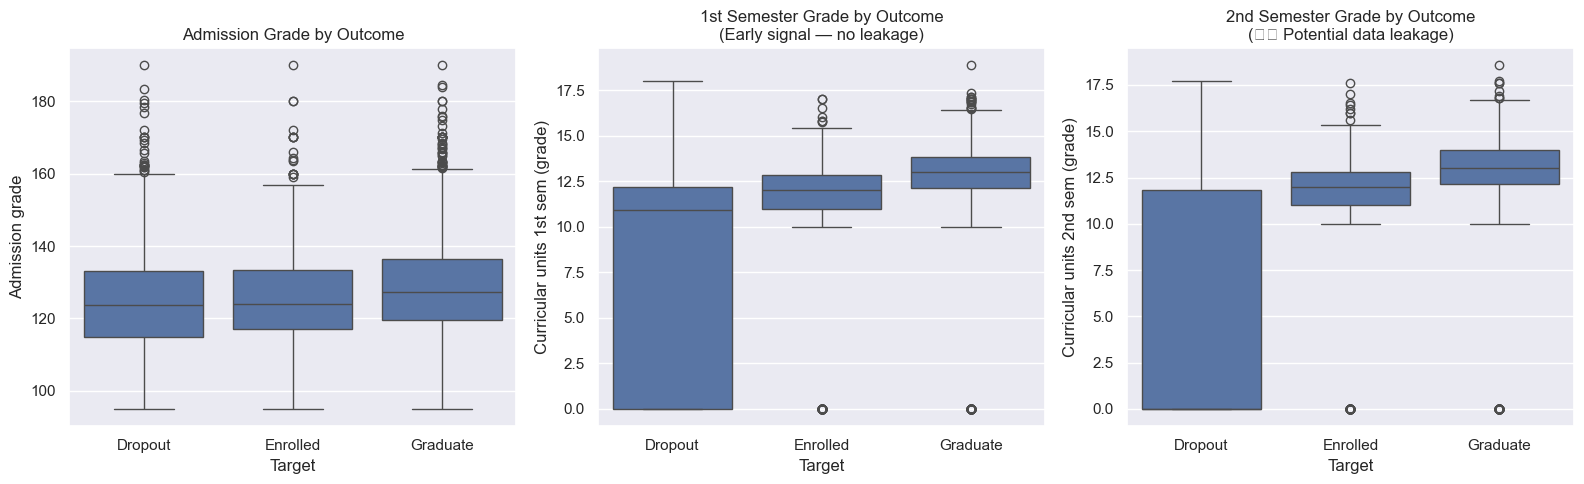

In [28]:
# ── EDA 2: 학업 성적 (핵심 신호) ─────────────────────────
# 가설: 학업에 어려움을 겪는 학생일수록 중도포기할 가능성이 높다.
# 1학기(일찍 알 수 있는 정보)와 2학기(데이터 누수 가능성)를 모두 확인한다.

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 입학 성적
sns.boxplot(data=df, x="Target", y="Admission grade",
            order=["Dropout", "Enrolled", "Graduate"], ax=axes[0])
axes[0].set_title("Admission Grade by Outcome", fontsize=12)

# 1학기 성적 (1학기 말에 알 수 있음)
sns.boxplot(data=df, x="Target", y="Curricular units 1st sem (grade)",
            order=["Dropout", "Enrolled", "Graduate"], ax=axes[1])
axes[1].set_title("1st Semester Grade by Outcome\n(Early signal — no leakage)", fontsize=12)

# 2학기 성적 (데이터 누수 위험)
sns.boxplot(data=df, x="Target", y="Curricular units 2nd sem (grade)",
            order=["Dropout", "Enrolled", "Graduate"], ax=axes[2])
axes[2].set_title("2nd Semester Grade by Outcome\n(⚠️ Potential data leakage)", fontsize=12)

plt.tight_layout()
plt.show()

**결과 해석: 학업 성적**

- 중도포기 학생은 입학 성적, 1학기 성적, 2학기 성적 모든 단계에서 졸업생보다 낮았습니다.
- 다만 차이는 입학 성적보다 학기 성적에서 훨씬 컸습니다. 입학 전부터 뒤처져 있었다기보다, 입학 후의 학업 어려움이 중도포기와 더 밀접하다고 판단했습니다.

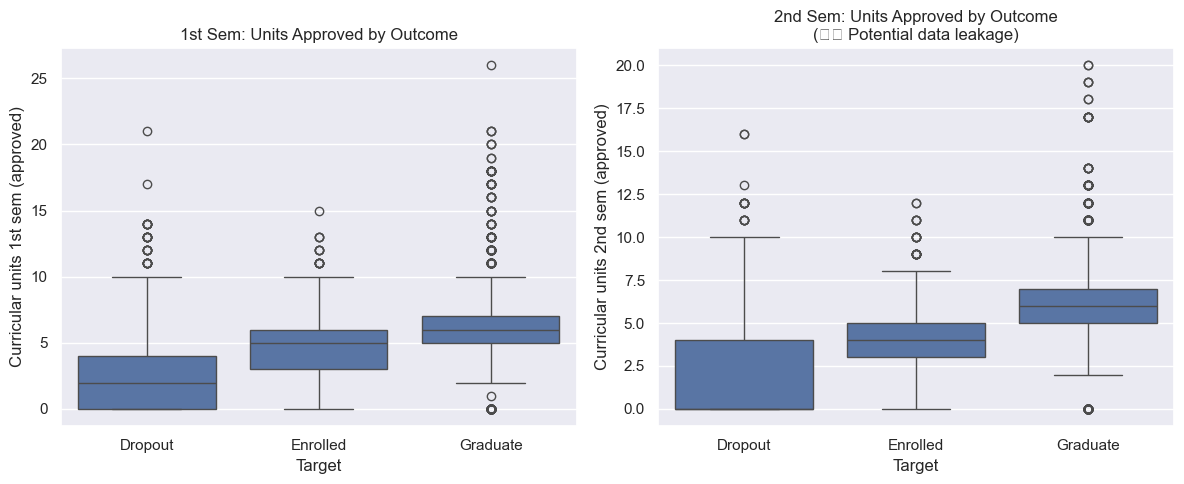

In [29]:
# ── EDA 3: 이수(통과) 과목 수 ────────────
# 이수 과목 수 = 실제로 통과한 과목 수. 성적만 볼 때보다 더 강한 신호다.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Target", y="Curricular units 1st sem (approved)",
            order=["Dropout", "Enrolled", "Graduate"], ax=axes[0])
axes[0].set_title("1st Sem: Units Approved by Outcome", fontsize=12)

sns.boxplot(data=df, x="Target", y="Curricular units 2nd sem (approved)",
            order=["Dropout", "Enrolled", "Graduate"], ax=axes[1])
axes[1].set_title("2nd Sem: Units Approved by Outcome\n(⚠️ Potential data leakage)", fontsize=12)

plt.tight_layout()
plt.show()

**결과 해석: 이수(통과) 과목 수**

- 중도포기 학생은 2학기에 통과한 과목이 0개에 가까운 경우가 많았습니다. 1학기 평균 통과 과목은 중도포기 약 2.6개, 졸업 약 6.2개였습니다.
- 2학기 이수 과목은 가장 강한 신호였지만, 이미 학교를 그만두는 중이라 시험을 보지 않은 학생이 섞여 있을 수 있었습니다. 그래서 미리 대응하는 목적에는 1학기 이수 과목 수가 더 적합한 신호라고 판단했습니다.

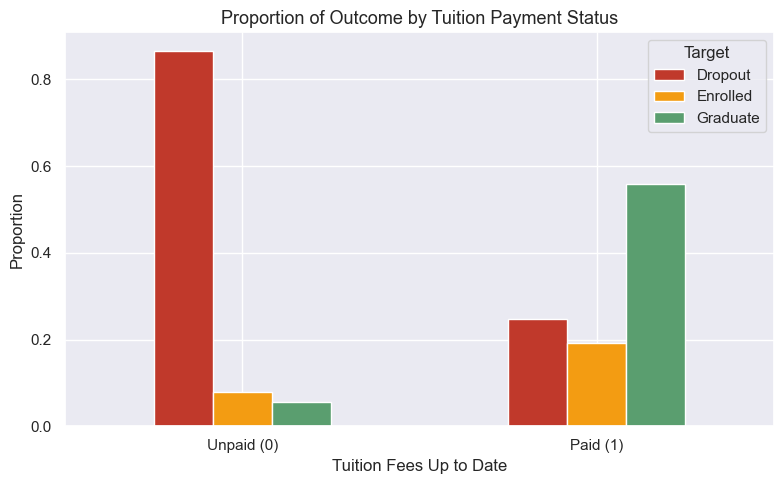

Mean 1st sem grade by tuition status:
Tuition fees up to date
0     7.346692
1    11.087254
Name: Curricular units 1st sem (grade), dtype: float64


In [30]:
# ── EDA 4: 경제적 요인 (등록금 납부 여부) ──────────────────────
# 질문: 경제적 부담은 학업 성적과 별개로 중도포기를 예측하는가?

tuition_prop = pd.crosstab(df["Tuition fees up to date"], df["Target"], normalize="index")
tuition_prop.index = ["Unpaid (0)", "Paid (1)"]

tuition_prop.plot(kind="bar", stacked=False, figsize=(8, 5),
                  color=["#c0392b", "#f39c12", "#5a9e6f"])
plt.title("Proportion of Outcome by Tuition Payment Status", fontsize=13)
plt.xlabel("Tuition Fees Up to Date")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.legend(title="Target")
plt.tight_layout()
plt.show()

# 등록금 납부와 성적이 서로 관련 있는지 확인 (교란 요인 점검)
print("Mean 1st sem grade by tuition status:")
print(df.groupby("Tuition fees up to date")["Curricular units 1st sem (grade)"].mean())

**결과 해석: 등록금 납부 여부**

- 등록금을 내지 못한 학생(528명)의 약 87%가 중도포기했고, 납부한 학생(3,896명)은 약 56%가 졸업했습니다. 1학기 평균 성적도 미납 학생 7.3점, 납부 학생 11.1점으로 차이가 컸습니다.
- 재정 어려움과 성적 부진이 함께 나타나는 경향이 확인되었습니다. 다만 등록금 미납이 중도포기의 원인인지, 이미 그만두려 해서 납부하지 않은 것인지는 이 데이터만으로 구분할 수 없었습니다.

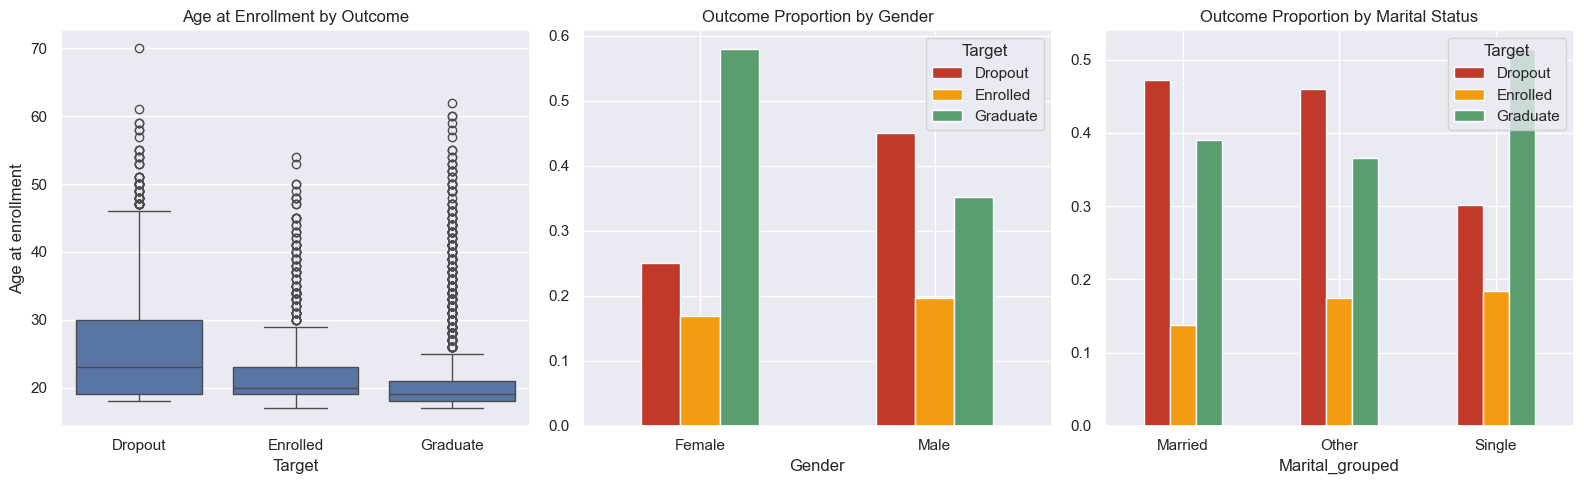

In [31]:
# ── EDA 5: 인구통계 요인 ──────────────────────
# 나이, 성별, 결혼 상태가 학업·경제 요인 외에
# 추가로 의미가 있는지 확인한다.

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 입학 당시 나이
sns.boxplot(data=df, x="Target", y="Age at enrollment",
            order=["Dropout", "Enrolled", "Graduate"], ax=axes[0])
axes[0].set_title("Age at Enrollment by Outcome", fontsize=12)

# 성별
gender_prop = pd.crosstab(df["Gender_label"], df["Target"], normalize="index")
gender_prop.plot(kind="bar", ax=axes[1], color=["#c0392b", "#f39c12", "#5a9e6f"])
axes[1].set_title("Outcome Proportion by Gender", fontsize=12)
axes[1].set_xlabel("Gender")
axes[1].tick_params(axis='x', rotation=0)

# 결혼 상태 (단순화)
marital_map = {1: "Single", 2: "Married", 3: "Widowed",
               4: "Divorced", 5: "Facto union", 6: "Legally separated"}
df["Marital_status_str"] = df["Marital status"].map(marital_map)
df["Marital_grouped"] = df["Marital_status_str"].apply(
    lambda x: x if x in ["Single", "Married"] else "Other"
)
marital_prop = pd.crosstab(df["Marital_grouped"], df["Target"], normalize="index")
marital_prop.plot(kind="bar", ax=axes[2], color=["#c0392b", "#f39c12", "#5a9e6f"])
axes[2].set_title("Outcome Proportion by Marital Status", fontsize=12)
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

**결과 해석: 나이, 성별, 결혼 상태**

- 나이, 성별, 결혼 상태에 따른 차이는 성적이나 이수 과목 수보다 작았습니다.
- 그래서 이 변수들만으로 중도포기를 설명하기는 어렵고, 학업·재정 변수와 함께 쓸 때 보조적으로 기여하는 정도로 보았습니다.

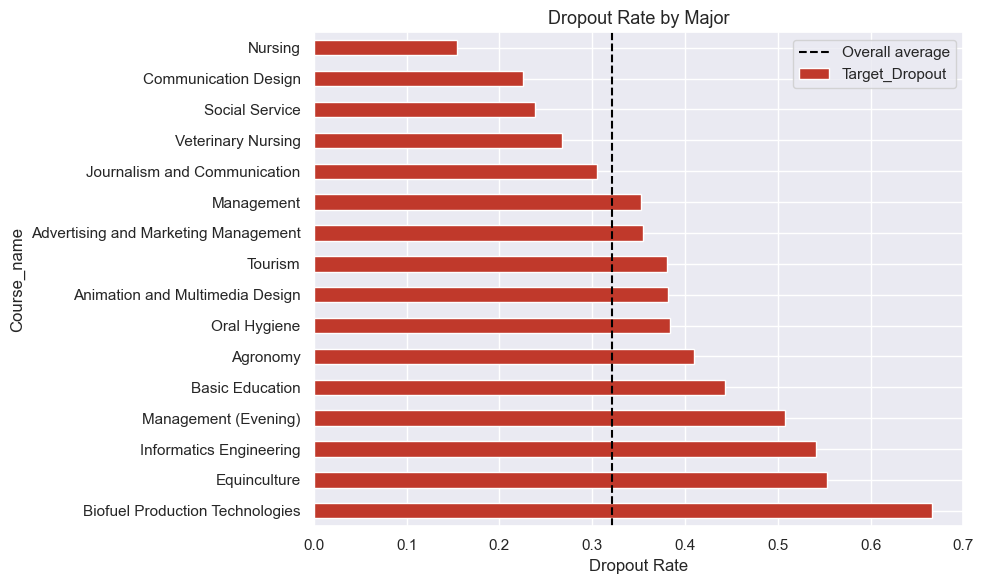

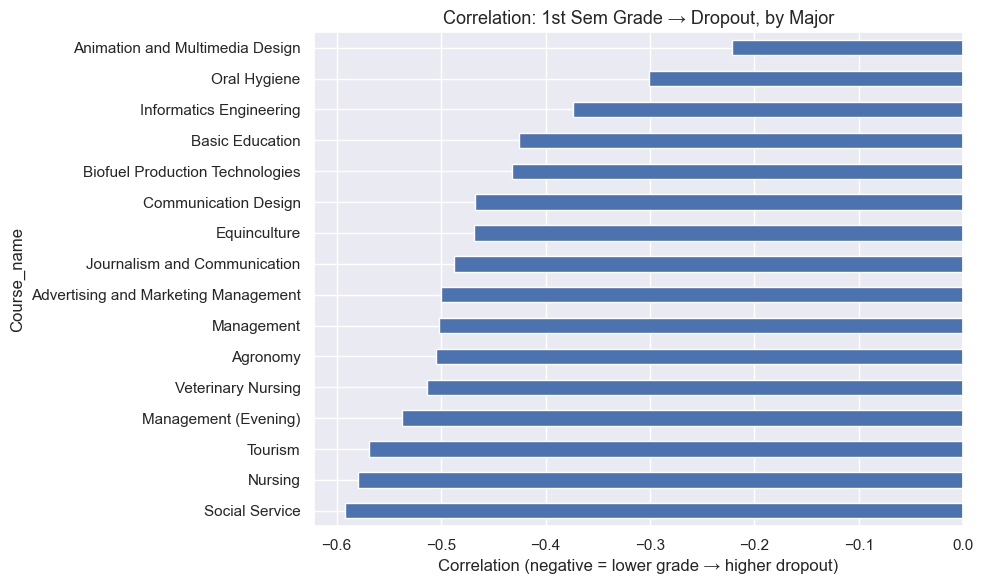

In [32]:
# ── EDA 6: 전공별 차이 ───────────────────
# 전공별 중도포기율과, 성적-중도포기 상관관계가
# 전공마다 다른지를 함께 확인한다.

# 전공별 중도포기율
course_dropout = df.groupby("Course_name")["Target_Dropout"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
course_dropout.plot(kind="barh", color="#c0392b")
plt.axvline(x=df["Target_Dropout"].mean(), color="black", linestyle="--", label="Overall average")
plt.title("Dropout Rate by Major", fontsize=13)
plt.xlabel("Dropout Rate")
plt.legend()
plt.tight_layout()
plt.show()

# 전공별 성적-중도포기 상관관계
course_corr = df.groupby("Course_name").apply(
    lambda x: x["Curricular units 1st sem (grade)"].corr(x["Target_Dropout"])
).sort_values()

plt.figure(figsize=(10, 6))
course_corr.plot(kind="barh")
plt.title("Correlation: 1st Sem Grade → Dropout, by Major", fontsize=13)
plt.xlabel("Correlation (negative = lower grade → higher dropout)")
plt.tight_layout()
plt.show()

**결과 해석: 전공별 중도포기율**

- 전공마다 중도포기율은 달랐지만, "성적이 낮을수록 중도포기가 많다"는 방향은 거의 모든 전공에서 같았습니다.
- 따라서 학업 성적은 전공과 관계없이 유효한 신호로 판단했습니다. 다만 전공마다 학생 수가 달라, 학생이 적은 전공의 비율은 변동이 클 수 있었습니다.

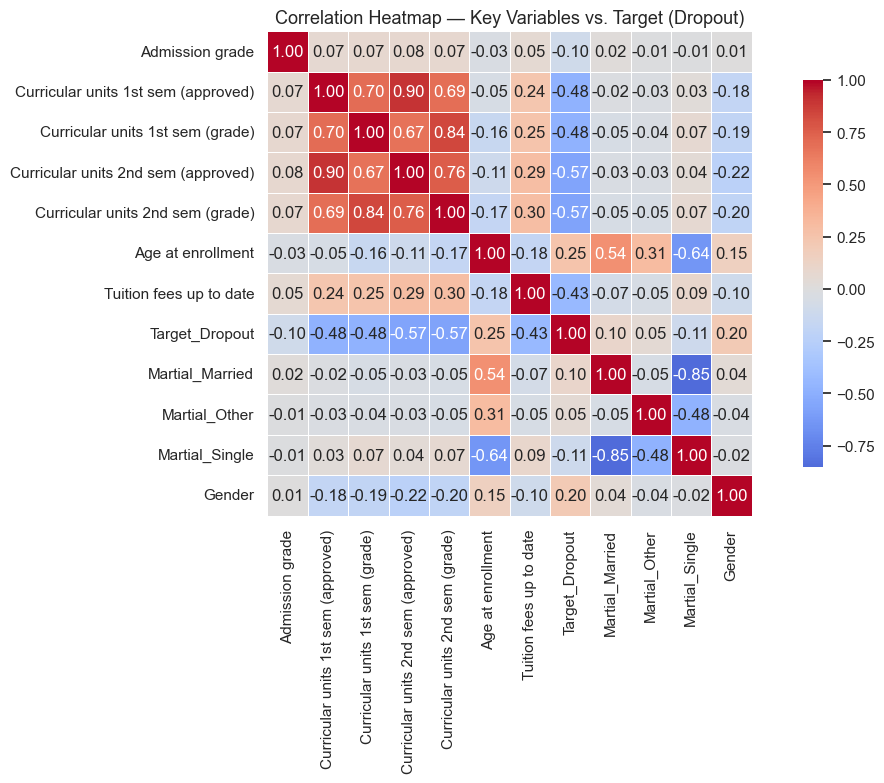

Correlation with Dropout (ranked):
Curricular units 2nd sem (grade)      -0.571792
Curricular units 2nd sem (approved)   -0.569500
Curricular units 1st sem (grade)      -0.480669
Curricular units 1st sem (approved)   -0.479112
Tuition fees up to date               -0.429149
Martial_Single                        -0.113859
Admission grade                       -0.095806
Martial_Other                          0.051011
Martial_Married                        0.099048
Gender                                 0.203983
Age at enrollment                      0.254215


In [33]:
# ── EDA 7: 상관관계 히트맵 ───────────────
# 어떤 변수가 중도포기와 상관이 있는지 정리한다.
# 모델링에 쓸 변수를 고르는 근거가 된다.

matrial_dummies = pd.get_dummies(df["Marital_grouped"], prefix="Martial")
df_heatmap = pd.concat([df, matrial_dummies], axis=1)

selected_cols = [
    "Admission grade",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Age at enrollment",
    "Tuition fees up to date",
    "Target_Dropout",
    "Martial_Married",
    "Martial_Other",
    "Martial_Single",
    "Gender"
]

corr = df_heatmap[selected_cols].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True,
            fmt=".2f", square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap — Key Variables vs. Target (Dropout)", fontsize=13)
plt.tight_layout()
plt.show()

# 중도포기와의 상관계수를 큰 순서대로 출력
dropout_corr = corr["Target_Dropout"].drop("Target_Dropout").sort_values()
print("Correlation with Dropout (ranked):")
print(dropout_corr.to_string())

**결과 해석: 상관관계 요약**

- 중도포기와 가장 강하게 연결된 것은 학업 변수였습니다. 2학기 성적·이수 과목(약 -0.57), 1학기 성적·이수 과목(약 -0.48) 모두 성적이 낮을수록 중도포기와 가까웠고, 그다음이 등록금 납부 여부(-0.43)였습니다.
- 나이(0.25)와 성별(0.20)은 그보다 약했습니다. 다만 입학 성적(-0.10)이나 결혼 상태보다는 높아서, "인구통계 변수가 가장 약하다"기보다 "학업·재정 변수보다 약하다"고 보는 것이 정확하다고 판단했습니다.
- 상관관계는 함께 움직인다는 의미일 뿐 원인을 보여 주지 않습니다. 또한 1·2학기 성적과 이수 과목 수는 서로 매우 비슷한 정보를 담고 있다는 점을 이후 해석에서 고려했습니다.

## 1-3. 전처리 및 피처 엔지니어링

모델링에 앞서 전처리 방식을 정했고, 각 결정은 위 EDA 결과를 근거로 했습니다.

In [34]:
# ── 전처리 ─────────────────────────────────────────────────────────
# 결정 1: 이진 타깃 (중도포기 vs 중도포기 아님)
#   이유: 목표는 도움이 필요한 위험 학생을 찾는 것이다.
#   재학 중과 졸업은 모두 '중도포기하지 않음'으로 본다.

# 결정 2: 모든 변수(2학기 포함)를 쓰되, 데이터 누수 위험을 표시해 둔다
#   이유: 먼저 가장 성능이 좋은 모델을 만든 뒤,
#   2학기 변수를 빼서 실제 조기 경보 상황을 재현한다(Part 2).

# 결정 3: 범주형 변수는 원-핫 인코딩
# 결정 4: 클래스 불균형 때문에 F1을 주 지표로 쓴다
#   (SMOTE가 중도포기 재현율을 높일 수 있는지는 후속 과제로 남김 → Part 2에서 확인)

from sklearn.model_selection import train_test_split

df_clean = df.drop(columns=["Target", "Gender_label", "Nation_name",
                              "Nationality_grouped", "Marital_status_str",
                              "Marital_grouped", "Gender_diff"],
                   errors="ignore")

matrial_dummies = pd.get_dummies(df["Marital_grouped"], prefix="Martial")
df_clean = pd.concat([df_clean, matrial_dummies], axis=1)

obj_cols = df_clean.select_dtypes(include=["object"]).columns
df_encoded = pd.get_dummies(df_clean, columns=obj_cols, drop_first=True)

X = df_encoded.drop(columns=["Target_Dropout"])
y = df_encoded["Target_Dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=789, shuffle=True
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"Features:     {X_train.shape[1]}")
print(f"\nDropout rate in train: {y_train.mean():.1%}")
print(f"Dropout rate in test:  {y_test.mean():.1%}")

Training set: 3539 samples
Test set:     885 samples
Features:     54

Dropout rate in train: 31.6%
Dropout rate in test:  34.1%


**결과 해석: 전처리**

- 4,424명을 학습용 3,539명, 테스트용 885명으로 나눴고, 원-핫 인코딩 후 변수는 54개가 되었습니다.
- 중도포기 비율이 학습 31.6%, 테스트 34.1%로 조금 달랐습니다. 한 번만 나눠서 생긴 차이로, 이후 테스트 점수가 분할에 따라 어느 정도 달라질 수 있다고 보았습니다.

## 1-4. 모델링: 단순한 모델부터 단계적으로

**모델링 전략**

복잡도가 낮은 순서로 5개 모델을 비교했습니다.
1. **Decision Tree (의사결정나무)**: 해석하기 쉬운 가장 단순한 기준 모델
2. **Random Forest (랜덤 포레스트)**: 나무 여러 개를 합쳐 의사결정나무를 보완
3. **KNN**: 거리 기반 비교 기준 모델
4. **SVM**: 경계 기반 분류기
5. **Logistic Regression (로지스틱 회귀)**: 해석이 쉽고 표 형태 데이터에서 성능이 좋은 모델

이어서 **XGBoost** 등 부스팅 모델로 성능을 높이고, **SHAP**으로 모델이 무엇을 근거로 예측했는지 해석해 EDA 결과와 연결했습니다.

In [35]:
# ── 모델링 공통 함수 ────────────────────────────────────────────────────
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def evaluate_model(name, y_true, y_pred, y_train_true=None, y_train_pred=None):
    """Print accuracy, F1, classification report, and overfitting check."""
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    print(f"{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(f"  Test Accuracy : {acc:.4f}")
    print(f"  Test F1 Score : {f1:.4f}")
    if y_train_true is not None and y_train_pred is not None:
        train_acc = accuracy_score(y_train_true, y_train_pred)
        train_f1  = f1_score(y_train_true, y_train_pred)
        print(f"  Train Accuracy: {train_acc:.4f}  (gap: {train_acc - acc:+.4f})")
        print(f"  Train F1 Score: {train_f1:.4f}  (gap: {train_f1 - f1:+.4f})")
    print(f"\n{classification_report(y_true, y_pred, target_names=['No Dropout','Dropout'])}")
    return acc, f1

  Decision Tree
  Test Accuracy : 0.8508
  Test F1 Score : 0.7582
  Train Accuracy: 0.8632  (gap: +0.0124)
  Train F1 Score: 0.7675  (gap: +0.0093)

              precision    recall  f1-score   support

  No Dropout       0.85      0.94      0.89       583
     Dropout       0.85      0.69      0.76       302

    accuracy                           0.85       885
   macro avg       0.85      0.81      0.83       885
weighted avg       0.85      0.85      0.85       885



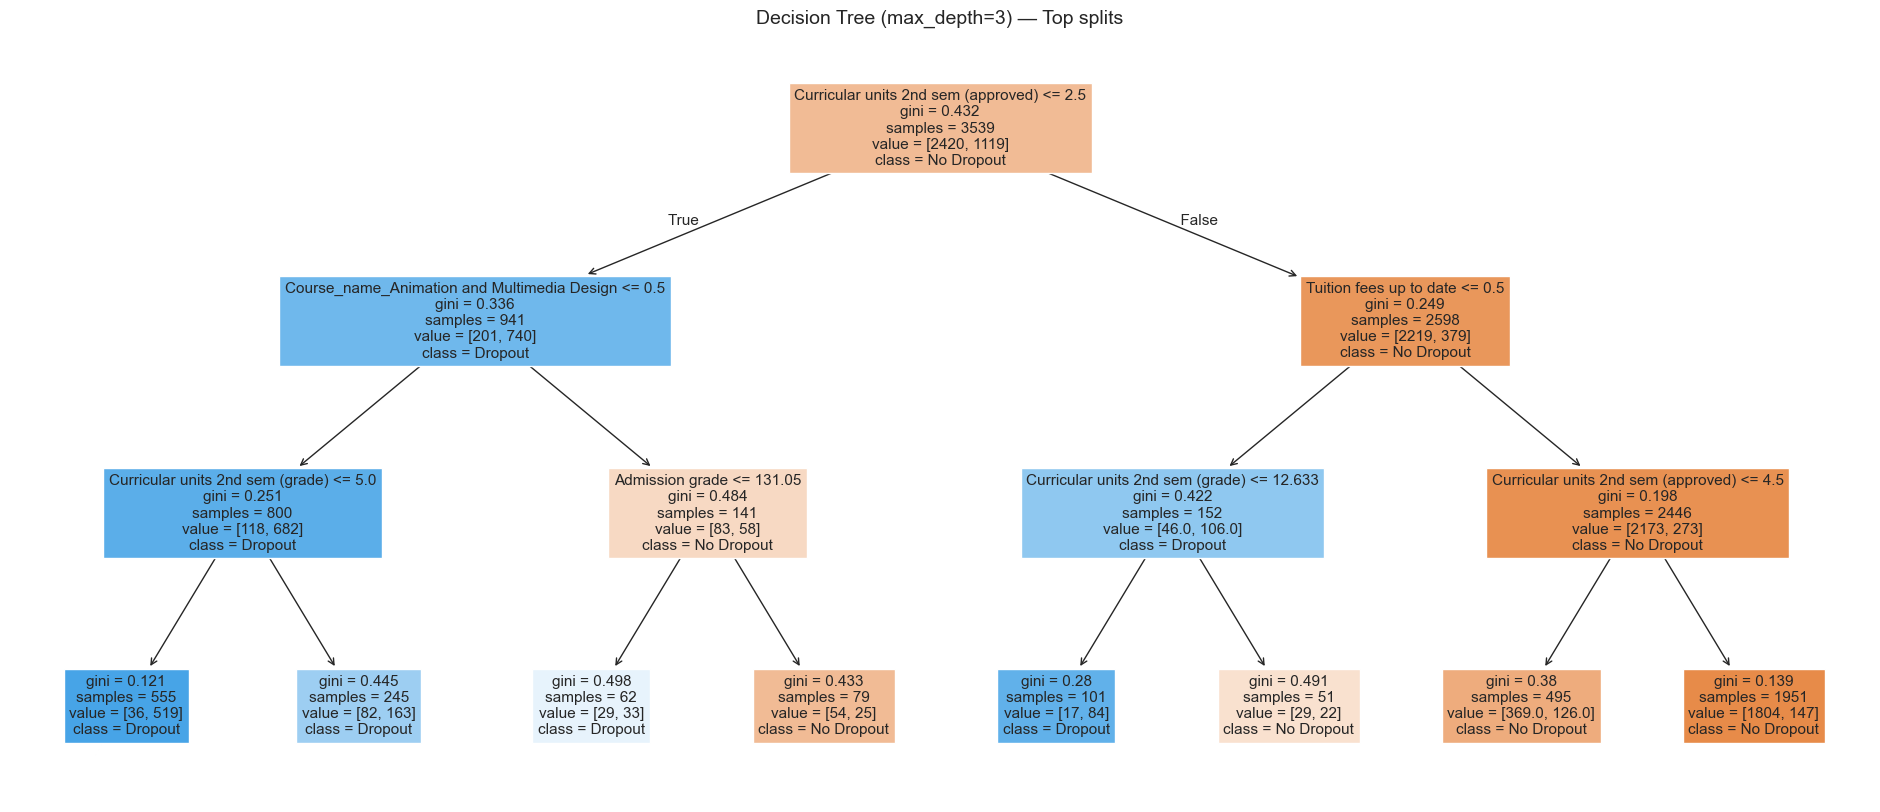

In [36]:
# ── 모델 1: 의사결정나무 ────────────────────────────────────────────────
# 이유: 해석하기 쉬운 기준 모델. 어떤 변수 하나가 데이터를 가르는지 보여 준다.
# 하이퍼파라미터: 과적합을 막고 읽기 쉽게 max_depth=3.
# 한계: 나무 하나는 불안정해서 데이터가 조금만 바뀌어도 분기가 달라질 수 있다.

from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=789)
dt.fit(X_train, y_train)

y_pred_dt       = dt.predict(X_test)
y_train_pred_dt = dt.predict(X_train)

acc_dt, f1_dt = evaluate_model(
    "Decision Tree", y_test, y_pred_dt, y_train, y_train_pred_dt
)

# 시각화
plt.figure(figsize=(24, 10))
plot_tree(dt, filled=True, feature_names=X.columns, fontsize=11,
          class_names=["No Dropout", "Dropout"])
plt.title("Decision Tree (max_depth=3) — Top splits", fontsize=14)
plt.show()

**결과 해석: 의사결정나무**

- 정확도 85.1%, F1 0.758이었습니다. 학습과 테스트 점수 차이가 작아 과적합은 심하지 않은 것으로 판단했습니다.
- 나무의 첫 분기가 "2학기 이수 과목 수"였습니다. 가장 강한 신호이지만 조기 경보에는 쓸 수 없는 정보라 데이터 누수 가능성을 표시해 두었습니다. 두 번째 분기 근처에 등록금 납부 여부가 나온 것은 EDA 결과와 일치했습니다.

  Random Forest
  Test Accuracy : 0.8520
  Test F1 Score : 0.7436
  Train Accuracy: 0.8740  (gap: +0.0220)
  Train F1 Score: 0.7720  (gap: +0.0283)

              precision    recall  f1-score   support

  No Dropout       0.83      0.97      0.90       583
     Dropout       0.91      0.63      0.74       302

    accuracy                           0.85       885
   macro avg       0.87      0.80      0.82       885
weighted avg       0.86      0.85      0.84       885



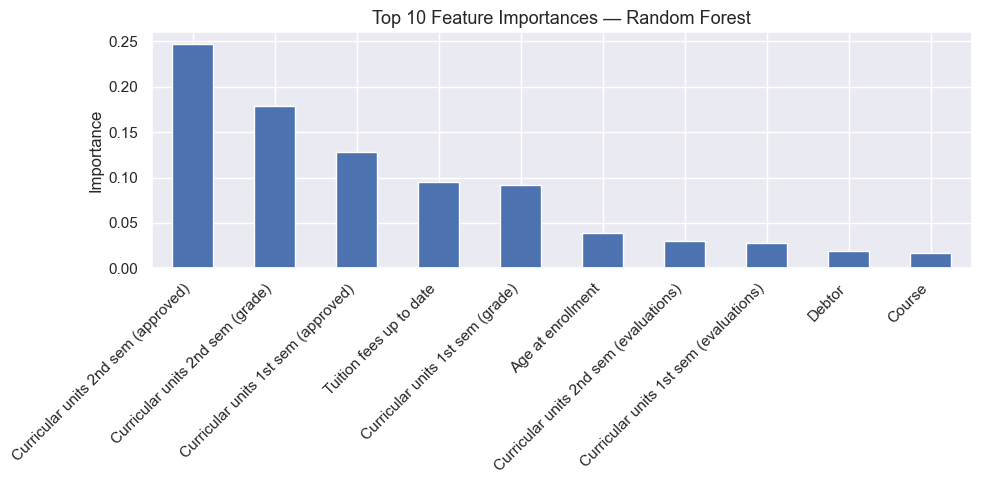

In [37]:
# ── 모델 2: 랜덤 포레스트 ────────────────────────────────────────────────
# 이유: 나무 여러 개를 합쳐 분산을 줄인다. 의사결정나무 하나보다 안정적이다.
# 하이퍼파라미터: n_estimators=300(충분한 나무 수), max_depth=5(과적합 조절).
# 기대: 잡음이 평균으로 상쇄되어 의사결정나무보다 F1이 높을 것.

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=789
)
rf.fit(X_train, y_train)

y_pred_rf       = rf.predict(X_test)
y_train_pred_rf = rf.predict(X_train)

acc_rf, f1_rf = evaluate_model(
    "Random Forest", y_test, y_pred_rf, y_train, y_train_pred_rf
)

# 변수 중요도
importances   = pd.Series(rf.feature_importances_, index=X.columns)
top10         = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top10.plot(kind="bar")
plt.title("Top 10 Feature Importances — Random Forest", fontsize=13)
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**결과 해석: 랜덤 포레스트**

- 정확도 85.2%, F1 0.744였습니다. 중도포기로 예측한 학생 중 실제 중도포기 비율(정밀도)은 0.91로 높았지만, 실제 중도포기 학생 중 찾아낸 비율(재현율)은 0.63으로 놓치는 학생이 많았습니다.
- 중요 변수 상위권이 2학기 변수와 등록금으로, EDA 결과와 일치했습니다.

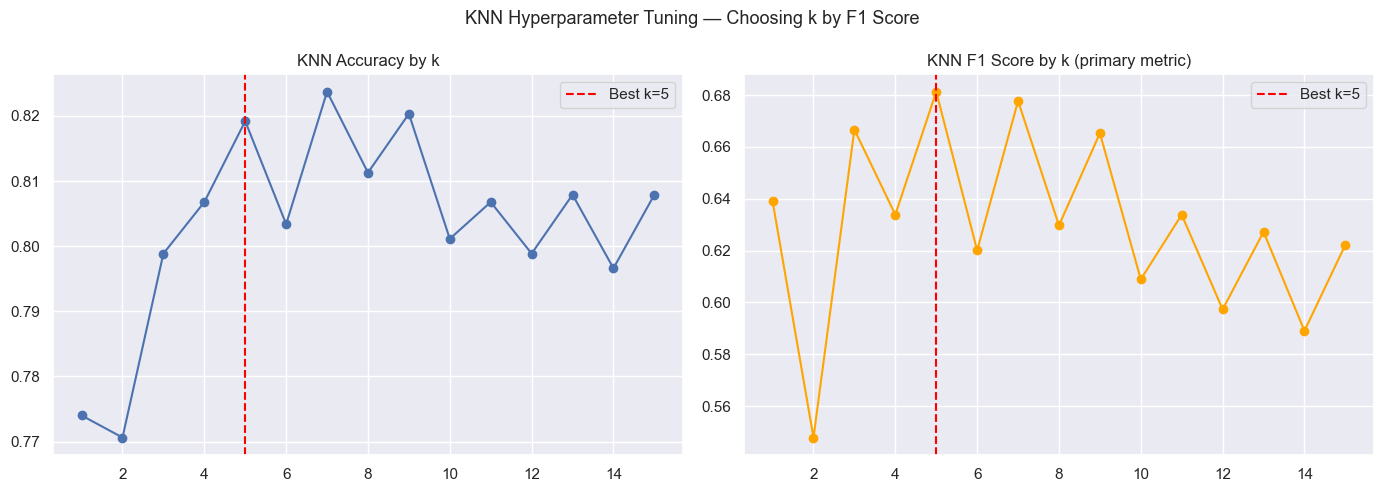

Best k by F1: 5
  KNN (k=5)
  Test Accuracy : 0.8192
  Test F1 Score : 0.6813
  Train Accuracy: 0.8689  (gap: +0.0497)
  Train F1 Score: 0.7596  (gap: +0.0783)

              precision    recall  f1-score   support

  No Dropout       0.81      0.95      0.87       583
     Dropout       0.85      0.57      0.68       302

    accuracy                           0.82       885
   macro avg       0.83      0.76      0.78       885
weighted avg       0.82      0.82      0.81       885


In [38]:
# ── 모델 3: KNN ──────────────────────────────────────────────────────────
# 이유: 비모수 기준 모델. 비슷한 학생끼리 묶는 방식이 통하는지 확인한다.
# 한계: 원-핫 인코딩된 범주형 변수가 많으면 거리 계산이 왜곡될 수 있다.
# 여러 k 값을 그려 보며 k를 정한다.

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 가장 좋은 k 찾기
k_values   = range(1, 16)
acc_scores = []
f1_scores  = []

for k in k_values:
    knn_tmp = Pipeline([("scaler", StandardScaler()),
                        ("knn", KNeighborsClassifier(n_neighbors=k))])
    knn_tmp.fit(X_train, y_train)
    y_tmp = knn_tmp.predict(X_test)
    acc_scores.append(accuracy_score(y_test, y_tmp))
    f1_scores.append(f1_score(y_test, y_tmp))

best_k = k_values[np.argmax(f1_scores)]  # 정확도가 아니라 F1 기준으로 k 선택

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_values, acc_scores, marker="o")
axes[0].axvline(best_k, color="red", linestyle="--", label=f"Best k={best_k}")
axes[0].set_title("KNN Accuracy by k"); axes[0].legend()
axes[1].plot(k_values, f1_scores, marker="o", color="orange")
axes[1].axvline(best_k, color="red", linestyle="--", label=f"Best k={best_k}")
axes[1].set_title("KNN F1 Score by k (primary metric)"); axes[1].legend()
plt.suptitle("KNN Hyperparameter Tuning — Choosing k by F1 Score", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Best k by F1: {best_k}")

# 가장 좋은 k로 최종 KNN 학습
knn_model = Pipeline([("scaler", StandardScaler()),
                      ("knn", KNeighborsClassifier(n_neighbors=best_k))])
knn_model.fit(X_train, y_train)
y_pred_knn       = knn_model.predict(X_test)
y_train_pred_knn = knn_model.predict(X_train)

acc_knn, f1_knn = evaluate_model(
    f"KNN (k={best_k})", y_test, y_pred_knn, y_train, y_train_pred_knn
)

**결과 해석: KNN**

- 정확도 81.9%, F1 0.681로 다섯 모델 중 가장 낮았습니다.
- 범주형 변수를 원-핫 인코딩해 변수 수가 늘면서 "가까운 이웃"을 찾는 거리 계산이 의미를 잃은 것으로 보았고, 이 데이터에는 거리 기반 방식이 잘 맞지 않는다고 판단했습니다.

In [39]:
# ── 모델 4: SVM ──────────────────────────────────────────────────────────
# 이유: 중도포기와 중도포기 아님 사이의 간격이 가장 넓은 경계를 찾는다.
# RBF 커널로 비선형 패턴을 다룬다. 표준화(StandardScaler)가 필요하다.
# 트레이드오프: 내부를 들여다보기 어려워 로지스틱 회귀보다 해석이 어렵다.

from sklearn.svm import SVC

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", random_state=789))
])
svm_model.fit(X_train, y_train)

y_pred_svm       = svm_model.predict(X_test)
y_train_pred_svm = svm_model.predict(X_train)

acc_svm, f1_svm = evaluate_model(
    "SVM (RBF kernel)", y_test, y_pred_svm, y_train, y_train_pred_svm
)

  SVM (RBF kernel)
  Test Accuracy : 0.8644
  Test F1 Score : 0.7683
  Train Accuracy: 0.9031  (gap: +0.0387)
  Train F1 Score: 0.8289  (gap: +0.0606)

              precision    recall  f1-score   support

  No Dropout       0.85      0.97      0.90       583
     Dropout       0.92      0.66      0.77       302

    accuracy                           0.86       885
   macro avg       0.88      0.81      0.84       885
weighted avg       0.87      0.86      0.86       885



**결과 해석: SVM**

- 정확도 86.4%, F1 0.768이었습니다. 정밀도 0.92는 높았지만 재현율 0.66은 낮은 편이었습니다.
- 학습 정확도(90.3%)가 테스트(86.4%)보다 높아 약간의 과적합 경향이 있는 것으로 보았습니다.

In [40]:
# ── 모델 5: 로지스틱 회귀 ──────────────────────────────────────────
# 이유: 표 형태 데이터에서 해석 가능성과 성능의 균형이 가장 좋다.
# class_weight='balanced'로 SMOTE 없이 클래스 불균형을 보정한다.
# 오즈비(statsmodels)로 통계적으로 해석할 수 있다.

from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    random_state=789, max_iter=2000, class_weight="balanced"
)
log_reg.fit(X_train, y_train)

y_pred_log       = log_reg.predict(X_test)
y_train_pred_log = log_reg.predict(X_train)

acc_log, f1_log = evaluate_model(
    "Logistic Regression", y_test, y_pred_log, y_train, y_train_pred_log
)

  Logistic Regression
  Test Accuracy : 0.8655
  Test F1 Score : 0.8007
  Train Accuracy: 0.8695  (gap: +0.0039)
  Train F1 Score: 0.8009  (gap: +0.0002)

              precision    recall  f1-score   support

  No Dropout       0.89      0.90      0.90       583
     Dropout       0.81      0.79      0.80       302

    accuracy                           0.87       885
   macro avg       0.85      0.85      0.85       885
weighted avg       0.86      0.87      0.87       885



**결과 해석: 로지스틱 회귀**

- 정확도 86.6%, F1 0.801로 다섯 모델 중 가장 좋았습니다. 중도포기 학생에 대한 정밀도 0.81, 재현율 0.79로 균형도 잘 맞았습니다.
- 학습과 테스트 점수가 거의 같아(정확도 차이 0.004) 과적합 없이 안정적인 것으로 확인되었습니다. 가장 단순한 모델이 복잡한 모델과 비슷한 성능을 냈다는 점을 중요하게 보았습니다.

In [41]:
# ── 로지스틱 회귀: 오즈비 해석 ────────────────────────
# 어떤 변수가 중도포기 위험을 유의하게 높이는가?
# 오즈비 > 1 → 중도포기 위험을 높임
# 오즈비 < 1 → 중도포기 위험을 낮춤(보호 요인)

import statsmodels.api as sm

X_sm = X.copy().astype(float)
X_sm = sm.add_constant(X_sm)

logit_model = sm.Logit(y, X_sm)
result      = logit_model.fit(disp=0)

summary_df = pd.DataFrame({
    "Coefficient": result.params,
    "Odds Ratio":  np.exp(result.params),
    "P-value":     result.pvalues
})

sig = summary_df[summary_df["P-value"] < 0.05].sort_values("Odds Ratio", ascending=False)
print("Statistically significant variables (p < 0.05):")
print(sig[["Odds Ratio", "P-value"]].to_string())
print()
print("Protective factors (OR < 1 → lower dropout risk):")
print(sig[sig["Odds Ratio"] < 1][["Odds Ratio", "P-value"]].to_string())
print()
print("Risk factors (OR > 1 → higher dropout risk):")
print(sig[sig["Odds Ratio"] > 1][["Odds Ratio", "P-value"]].to_string())

Statistically significant variables (p < 0.05):
                                     Odds Ratio       P-value
Curricular units 2nd sem (enrolled)    1.589754  9.440770e-06
Debtor                                 1.541157  1.101106e-02
Gender                                 1.400515  3.499521e-03
Displaced                              1.323538  1.829360e-02
Curricular units 2nd sem (credited)    1.244376  1.342727e-02
Curricular units 1st sem (credited)    1.188992  3.493137e-02
Application order                      1.105739  2.302174e-02
Unemployment rate                      1.095760  2.454576e-05
Curricular units 1st sem (grade)       1.062353  1.365099e-02
Age at enrollment                      1.049664  3.061785e-06
Nacionality                            1.038121  6.620066e-04
Mother's qualification                 1.011405  5.157417e-03
Mother's occupation                    0.988006  1.746313e-02
Curricular units 2nd sem (grade)       0.938043  5.511101e-03
Curricular units 1st s

**결과 해석: 오즈비(Odds Ratio)**

오즈비는 변수가 한 단위 커질 때 중도포기 가능성이 몇 배가 되는지를 나타냅니다. 1보다 작으면 위험을 낮추고, 1보다 크면 위험을 높이는 방향입니다.

- 위험을 낮추는 쪽: 등록금 납부(0.09), 2학기 이수 과목(0.54), 1학기 이수 과목(0.72), 장학금 수혜(0.60)
- 위험을 높이는 쪽: 2학기 등록 과목 수(1.59), 채무 상태(1.54), 성별 코드(1.40), 나이(1.05)
- 해석할 때 두 가지를 주의했습니다. 첫째, 1학기 성적의 오즈비가 1.06으로 나와 "성적이 높을수록 위험하다"처럼 읽혔는데, 비슷한 정보를 가진 변수(1학기 이수 과목 등)가 함께 들어가 생긴 현상으로 판단했습니다. 그래서 개별 계수를 그대로 해석하지 않았습니다. 둘째, 국적·전공 같은 코드 변수의 계수는 숫자 자체에 의미가 없어 해석에서 제외했습니다.

## 1-5. 부스팅 모델

그래디언트 부스팅 계열은 표 형태 데이터에서 개별 분류기보다 성능이 좋은 경우가 많아 추가로 비교했습니다.
XGBoost, LightGBM, CatBoost를 비교한 뒤, XGBoost에 **SHAP**을 적용해 모델이 *왜* 그렇게 예측했는지 확인하고 EDA 결과와 연결했습니다.

In [42]:
# ── 부스팅: XGBoost ─────────────────────────────────────────────────────
# scale_pos_weight로 클래스 불균형 보정 (음성 클래스 수 ÷ 양성 클래스 수)
# 부스팅 모델에서 class_weight='balanced'와 같은 역할

from xgboost import XGBClassifier

neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=neg_pos_ratio,  # 클래스 불균형 보정
    random_state=789,
    eval_metric="logloss",
    use_label_encoder=False
)
xgb_model.fit(X_train, y_train)

y_pred_xgb       = xgb_model.predict(X_test)
y_train_pred_xgb = xgb_model.predict(X_train)

acc_xgb, f1_xgb = evaluate_model(
    "XGBoost", y_test, y_pred_xgb, y_train, y_train_pred_xgb
)

  XGBoost
  Test Accuracy : 0.8768
  Test F1 Score : 0.8124
  Train Accuracy: 0.9330  (gap: +0.0562)
  Train F1 Score: 0.8953  (gap: +0.0829)

              precision    recall  f1-score   support

  No Dropout       0.89      0.93      0.91       583
     Dropout       0.85      0.78      0.81       302

    accuracy                           0.88       885
   macro avg       0.87      0.85      0.86       885
weighted avg       0.88      0.88      0.88       885



In [43]:
# ── 부스팅: LightGBM ────────────────────────────────────────────────────
# 학습이 빠르고 큰 데이터에 적합
# is_unbalance=True로 클래스 불균형 보정

from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    is_unbalance=True,  # 클래스 불균형 보정
    random_state=789,
    verbose=-1
)
lgbm_model.fit(X_train, y_train)

y_pred_lgbm       = lgbm_model.predict(X_test)
y_train_pred_lgbm = lgbm_model.predict(X_train)

acc_lgbm, f1_lgbm = evaluate_model(
    "LightGBM", y_test, y_pred_lgbm, y_train, y_train_pred_lgbm
)

  LightGBM
  Test Accuracy : 0.8723
  Test F1 Score : 0.8062
  Train Accuracy: 0.9373  (gap: +0.0650)
  Train F1 Score: 0.9015  (gap: +0.0953)

              precision    recall  f1-score   support

  No Dropout       0.89      0.92      0.90       583
     Dropout       0.84      0.78      0.81       302

    accuracy                           0.87       885
   macro avg       0.86      0.85      0.86       885
weighted avg       0.87      0.87      0.87       885



In [46]:
# ── 부스팅: CatBoost ────────────────────────────────────────────────────
# 범주형 변수를 별도 인코딩 없이 직접 다룸
# auto_class_weights='Balanced'로 불균형 보정
!pip install catboost
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.05,
    auto_class_weights="Balanced",  # 클래스 불균형 보정
    random_seed=789,
    verbose=0
)
catboost_model.fit(X_train, y_train)

y_pred_cat       = catboost_model.predict(X_test)
y_train_pred_cat = catboost_model.predict(X_train)

acc_cat, f1_cat = evaluate_model(
    "CatBoost", y_test, y_pred_cat, y_train, y_train_pred_cat
)

  CatBoost
  Test Accuracy : 0.8621
  Test F1 Score : 0.7967
  Train Accuracy: 0.9084  (gap: +0.0463)
  Train F1 Score: 0.8590  (gap: +0.0623)

              precision    recall  f1-score   support

  No Dropout       0.89      0.90      0.90       583
     Dropout       0.80      0.79      0.80       302

    accuracy                           0.86       885
   macro avg       0.85      0.85      0.85       885
weighted avg       0.86      0.86      0.86       885


**결과 해석: 부스팅 모델**

- XGBoost 정확도 87.7%, F1 0.812 / LightGBM 87.2%, 0.806 / CatBoost 86.2%, 0.797로 모두 앞의 단일 모델들보다 조금 높았습니다.
- 다만 학습 점수가 테스트보다 훨씬 높았습니다(XGBoost 정확도 93.3% 대 87.7%). 학습 데이터에 지나치게 맞춰졌을 가능성이 있다고 보았습니다.

## 1-6. 모델 비교

              Model  Accuracy  F1 Score     Type
            XGBoost  0.876836  0.812392 Boosting
           LightGBM  0.872316  0.806175 Boosting
Logistic Regression  0.865537  0.800670   Linear
           CatBoost  0.862147  0.796667 Boosting
                SVM  0.864407  0.768340 Boundary
      Decision Tree  0.850847  0.758242     Tree
      Random Forest  0.851977  0.743640 Ensemble
                KNN  0.819209  0.681275 Distance


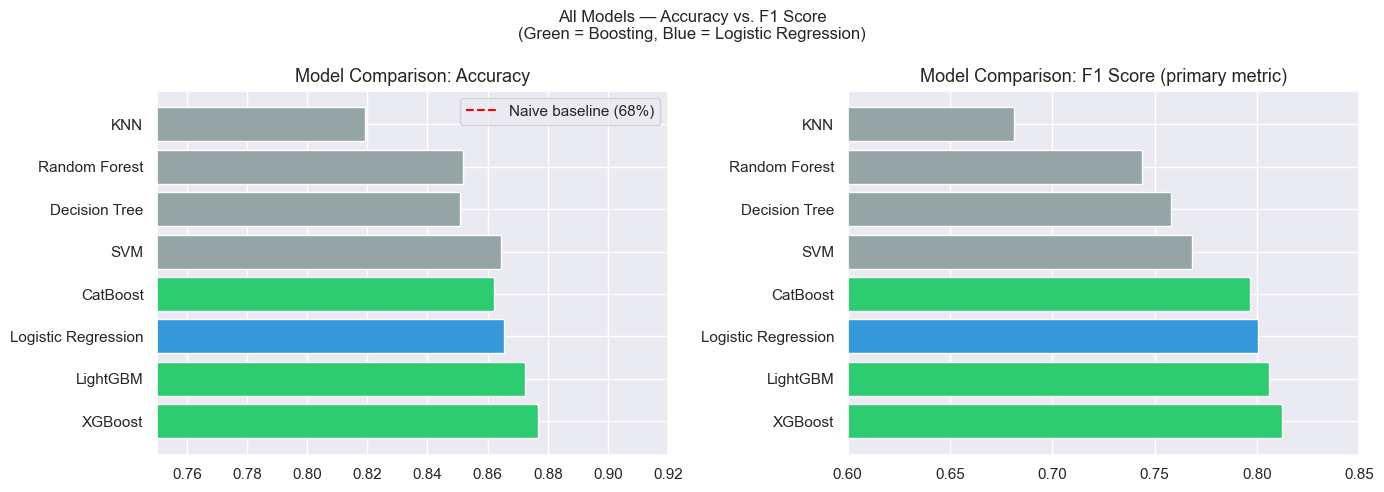


Best model by F1: XGBoost


In [47]:
# ── 모델 비교표 ────────────────────────────────────────────────
results = pd.DataFrame({
    "Model": [
        "Decision Tree", "Random Forest", "KNN",
        "SVM", "Logistic Regression",
        "XGBoost", "LightGBM", "CatBoost"
    ],
    "Accuracy": [
        acc_dt, acc_rf, acc_knn,
        acc_svm, acc_log,
        acc_xgb, acc_lgbm, acc_cat
    ],
    "F1 Score": [
        f1_dt, f1_rf, f1_knn,
        f1_svm, f1_log,
        f1_xgb, f1_lgbm, f1_cat
    ],
    "Type": [
        "Tree", "Ensemble", "Distance",
        "Boundary", "Linear",
        "Boosting", "Boosting", "Boosting"
    ]
}).sort_values("F1 Score", ascending=False).reset_index(drop=True)

print(results.to_string(index=False))

# 그래프로 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ["#2ecc71" if t == "Boosting" else "#3498db" if t == "Linear"
          else "#95a5a6" for t in results["Type"]]

axes[0].barh(results["Model"], results["Accuracy"], color=colors)
axes[0].set_xlim(0.75, 0.92)
axes[0].set_title("Model Comparison: Accuracy", fontsize=13)
axes[0].axvline(x=0.68, color="red", linestyle="--", label="Naive baseline (68%)")
axes[0].legend()

axes[1].barh(results["Model"], results["F1 Score"], color=colors)
axes[1].set_xlim(0.60, 0.85)
axes[1].set_title("Model Comparison: F1 Score (primary metric)", fontsize=13)

plt.suptitle("All Models — Accuracy vs. F1 Score\n(Green = Boosting, Blue = Logistic Regression)",
             fontsize=12)
plt.tight_layout()
plt.show()

best_model_name = results.iloc[0]["Model"]
print(f"\nBest model by F1: {best_model_name}")

**결과 해석: 모델 비교**

- F1 기준 순위는 XGBoost 0.812, LightGBM 0.806, 로지스틱 회귀 0.801, CatBoost 0.797, SVM 0.768, 의사결정나무 0.758, 랜덤 포레스트 0.744, KNN 0.681이었습니다.
- 상위 네 모델의 차이는 약 0.016 이내로 매우 작았습니다. 테스트를 한 번만 나눠 비교했기 때문에 이 정도 차이는 우연일 수 있다고 판단했습니다. 그래서 "XGBoost가 압도적으로 낫다"기보다 "상위 모델들은 비슷하고, 로지스틱 회귀처럼 설명하기 쉬운 모델도 충분히 경쟁력이 있다"고 결론지었습니다.

## 1-7. SHAP 해석: 모델은 무엇을 근거로 예측했는가

SHAP(SHapley Additive exPlanations)은 각 변수가 예측을 중도포기 쪽으로, 혹은 반대쪽으로 *얼마나* 움직였는지 보여 주는 방법입니다. 이를 통해 모델 결과를 EDA와 연결하고, **어떤 학생이 가장 위험하며 그 이유는 무엇인지** 확인했습니다.

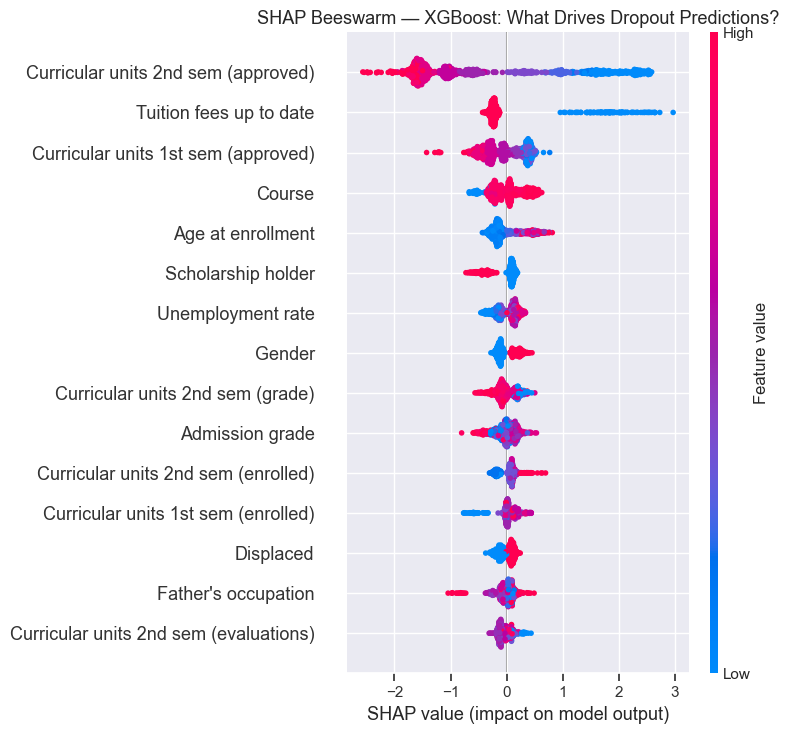

In [49]:
# ── XGBoost SHAP 분석 ──────────────────────────────────────────────
# XGBoost를 고른 이유: 성능이 좋고 SHAP을 기본으로 지원한다.
# SHAP 비스웜 그래프: 점 하나 = 학생 한 명.
#   색 = 변수 값 (빨강 = 높음, 파랑 = 낮음)
#   가로 위치 = SHAP 값 (오른쪽일수록 중도포기 쪽으로 예측을 밀어 올림)
import shap

explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test, plot_type="dot",
                  max_display=15, show=False)
plt.title("SHAP Beeswarm — XGBoost: What Drives Dropout Predictions?", fontsize=13)
plt.tight_layout()
plt.show()

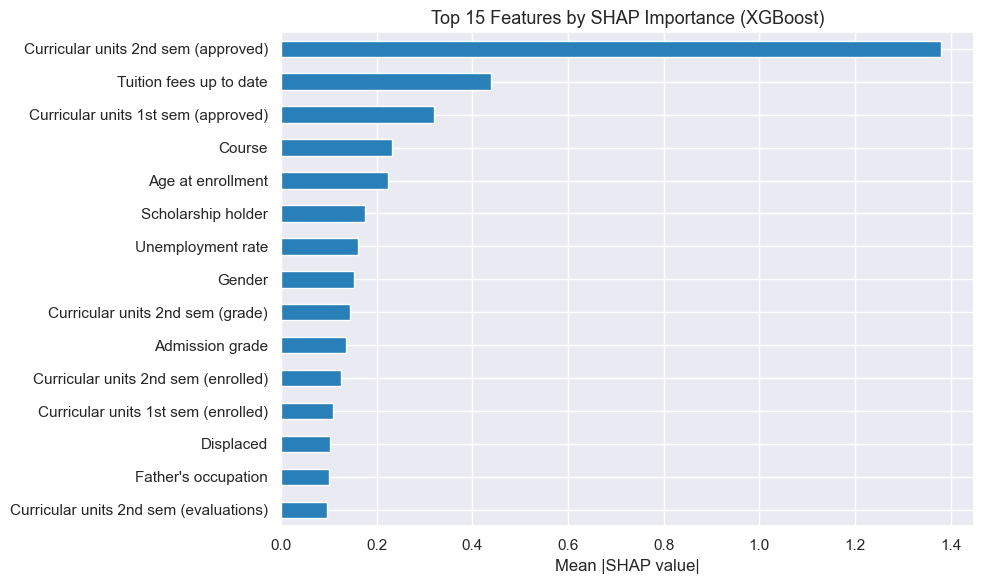

In [52]:
# ── SHAP: 모델 결과를 EDA와 다시 연결 ────────────────────────────────────
# SHAP 중요도를 막대그래프로 정리한다.

# SHAP 절댓값의 평균 = 변수 중요도
shap_importance = pd.DataFrame(
    np.abs(shap_values).mean(axis=0),
    index=X_test.columns,
    columns=["Mean |SHAP|"]
).sort_values("Mean |SHAP|", ascending=False)

top15 = shap_importance.head(15)

plt.figure(figsize=(10, 6))
top15["Mean |SHAP|"].plot(kind="barh", color="#2980b9")
plt.title("Top 15 Features by SHAP Importance (XGBoost)", fontsize=13)
plt.xlabel("Mean |SHAP value|")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**결과 해석: SHAP**

- 모델이 가장 크게 참고한 변수는 2학기 이수 과목 수, 등록금 납부 여부, 1학기 이수 과목 수 순이었습니다. 이수 과목이 적고 등록금을 내지 못한 학생일수록 중도포기 쪽으로 예측이 기울었습니다.
- 장학금 수혜는 중도포기 확률을 낮추는 방향으로 작용했습니다. 실제 중도포기 비율도 장학금이 없는 학생 약 39%, 있는 학생 약 12%였습니다. 다만 장학금이 원인인지, 원래 성적이 좋은 학생이 장학금을 받은 것인지는 구분할 수 없었습니다.
- 2학기 변수는 조기 경보에는 쓸 수 없는 정보였습니다. 실제 활용을 위해서는 1학기 변수 기준의 결과를 따로 봐야 한다고 판단했고, 이를 이 단계의 가장 큰 한계이자 다음 과제로 정리했습니다.
- SHAP은 모델이 무엇을 보고 판단했는지 설명하는 도구이며, 그 변수가 중도포기의 원인이라는 증거는 아닙니다.

## 1-8. 한계

1. **2학기 변수로 인한 데이터 누수**: `Curricular units 2nd sem (approved)` 같은 변수가 가장 강한 예측 변수였지만, 실제 조기 경보 시점에는 아직 얻을 수 없는 정보였습니다. 실제 운영 가능한 모델은 1학기 변수만으로 다시 검증해야 한다고 판단했습니다.

2. **클래스 불균형 처리**: 기본적인 불균형 보정으로 `class_weight='balanced'`와 `scale_pos_weight`를 사용했습니다. SMOTE(소수 클래스 사례를 인위적으로 늘리는 방법)는 이 단계에서 적용하지 않았고, 후속 과제로 남겼습니다.

3. **단일 데이터셋**: 결과는 포르투갈 한 교육기관의 데이터에 기반했습니다. 다른 기관, 국가, 교육 체계로 일반화되는지는 확인하지 못했습니다.

4. **이진 분류로의 단순화**: "재학 중(Enrolled)"을 "중도포기 아님"으로 합치면서 차이가 사라졌습니다. 아직 재학 중이지만 어려움을 겪는 학생은 이미 졸업한 학생과 상황이 다릅니다.

5. **시간 흐름 미반영**: 학생의 학업 경로는 시간에 따라 변합니다. 순차 모델(예: LSTM)이라면 정적 변수보다 성적 하락 추세를 더 잘 포착할 수 있었을 것입니다.

## 1-9. 후속 계획: 모델에서 조기 경보 시스템으로

SHAP 결과를 바탕으로, 개입을 연결할 수 있는 지점을 다음과 같이 정리했습니다.

| SHAP 결과 | 연결할 수 있는 개입 |
|---|---|
| 1학기 이수 과목이 적을수록 중도포기 | 1학기 종료 후 위험 학생을 표시하고 학업 상담 연결 |
| 등록금 미납 → 중도포기 | 2학기 시작 전 재정 지원 안내 |
| 장학금 수혜 학생은 중도포기가 적음 | 성적·소득 기반 장학 프로그램 검토 |
| 2학기 이수 과목이 적을수록 중도포기 | 학기 중간 점검과 튜터링 연계 |

**제안한 조기 경보 흐름**
1. 1학기 8주차 이후: 1학기 변수만 쓰는 모델로 모든 학생의 위험도 산출
2. 위험 기준을 넘는 학생에게 학업 상담 배정
3. 등록금 미납 학생에게 재정 지원 안내
4. 개입 결과를 추적해 매년 모델 재학습

**다음 모델링 단계로 정한 것**
- 1학기 변수만으로 재학습 (누수 제거)
- SMOTE 적용 시 재현율 개선 여부 비교
- 외부 데이터셋으로 일반화 가능성 검증
- 다중 클래스(중도포기 / 재학 중 / 졸업) 모델링

(이 중 앞의 두 가지와 다중 클래스는 Part 2에서 진행했습니다.)

# Part 2. 후속 분석: 1학기 말까지의 정보로 다시 분석

### 후속 분석: 1학기 정보만 사용, SMOTE, 다중 클래스
#### Team EduCare | Illini Data Science Club 프로젝트 후속 분석

Part 1의 한계와 후속 계획에서 남겨 둔 세 가지를 진행했습니다.

1. **1학기 변수만으로 다시 분석**: 2학기 정보(누수)를 빼고, 1학기가 끝난 시점에 쓸 수 있는 정보만 사용
2. **SMOTE 적용**: 중도포기 학생이 적은 불균형을 인위적으로 보정했을 때 재현율이 좋아지는지 확인
3. **다중 클래스 모델링**: 중도포기 / 재학 중 / 졸업 세 그룹을 모두 예측

**평가 방식도 바꿨습니다.** Part 1은 데이터를 한 번 나눠 점수를 냈지만, 여기서는 데이터를 5조각으로 나눠 돌아가며 평가하는 과정을 2번 반복(총 10회)해 평균과 변동을 함께 보았습니다. 한 번의 분할에서 나온 작은 차이는 우연일 수 있기 때문입니다.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings("ignore")
from matplotlib import font_manager
import os
# 한글 폰트 (환경에 있는 것을 자동 선택; 리눅스에서는 나눔고딕 파일이 있으면 등록)
_ng = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
if os.path.exists(_ng): font_manager.fontManager.addfont(_ng)
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"]:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
sns.set(style="whitegrid", font=plt.rcParams["font.family"][0])

from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, average_precision_score,
                             accuracy_score, balanced_accuracy_score, confusion_matrix)
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
SEED = 789

df = pd.read_csv("data.csv", sep=";")
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={"Nacionality": "Nationality"})
df["y"] = (df["Target"] == "Dropout").astype(int)                       # 이진: 1 = 중도포기
df["y3"] = df["Target"].map({"Dropout": 0, "Enrolled": 1, "Graduate": 2})  # 다중: 0 중도포기 / 1 재학 중 / 2 졸업
print("데이터:", df.shape, "| 결측:", int(df.isna().sum().sum()))
print(df["Target"].value_counts().to_string())

데이터: (4424, 39) | 결측: 0
Target
Graduate    2209
Dropout     1421
Enrolled     794


In [2]:
# 입학 시점 변수 / 재정 변수 / 1학기 변수 (2학기 변수는 사용하지 않음)
app = ["Marital status","Application mode","Application order","Course","Daytime/evening attendance","Previous qualification",
       "Previous qualification (grade)","Nationality","Mother's qualification","Father's qualification","Mother's occupation",
       "Father's occupation","Admission grade","Displaced","Educational special needs","Gender","Age at enrollment","International",
       "Unemployment rate","Inflation rate","GDP"]
fin  = ["Tuition fees up to date","Debtor","Scholarship holder"]       # 측정 시점이 문서에 명확하지 않은 재정 변수
sem1 = [c for c in df.columns if "1st sem" in c]
FEAT = app + fin + sem1                                                  # 1학기 말까지 알 수 있는 정보
cat_cols = ["Marital status","Application mode","Course","Previous qualification","Nationality",
            "Mother's qualification","Father's qualification","Mother's occupation","Father's occupation"]
print("사용 변수:", len(FEAT), "개  (입학", len(app), "+ 재정", len(fin), "+ 1학기", len(sem1), ")")
print("제외한 2학기 변수:", len([c for c in df.columns if "2nd sem" in c]), "개")

X, y, y3 = df[FEAT], df["y"], df["y3"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)   # 5조각 x 2회 = 10번 평가

def make_pre(scale=True):
    cats = [c for c in FEAT if c in cat_cols]; nums = [c for c in FEAT if c not in cat_cols]
    # 코드 번호(전공, 직업 등)는 숫자가 아니라 범주이므로 원-핫 인코딩, 1% 미만 희귀 값은 하나로 묶음
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), cats),
        ("num", StandardScaler() if scale else "passthrough", nums)])

pos_w = (y == 0).sum() / (y == 1).sum()

사용 변수: 30 개  (입학 21 + 재정 3 + 1학기 6 )
제외한 2학기 변수: 6 개


## 2-1. 1학기 변수만으로 다시 분석

**바꾼 점**
- 2학기 변수 6개를 모두 빼고, **입학 시점 + 재정 + 1학기** 변수만 사용했습니다. 1학기가 끝난 시점에 실제로 알 수 있는 정보입니다.
- 평가는 반복 교차 검증으로 했고, 점수는 평균과 표준편차를 함께 표시했습니다.

**사용한 지표**
- **F1**: 중도포기 학생을 놓치지 않는 정도와 잘못 지목하지 않는 정도를 합친 점수
- **ROC-AUC**: 중도포기 학생과 그렇지 않은 학생을 한 쌍 뽑았을 때 누가 중도포기할지 맞힐 확률 (0.5는 무작위, 1은 완벽)
- **PR-AUC**: 중도포기 학생이 적은 상황에서 위험 순위를 얼마나 잘 매기는지

In [3]:
def build(name):
    if name == "LogReg":
        est = LogisticRegressionCV(Cs=8, cv=3, scoring="roc_auc", max_iter=3000, class_weight="balanced", random_state=SEED)
        return Pipeline([("pre", make_pre()), ("m", est)])
    if name == "XGBoost":
        est = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                            scale_pos_weight=pos_w, eval_metric="logloss", random_state=SEED, n_jobs=2)
        return Pipeline([("pre", make_pre(False)), ("m", est)])
    if name == "LightGBM":
        est = LGBMClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             class_weight="balanced", random_state=SEED, verbose=-1, n_jobs=2)
        return Pipeline([("pre", make_pre(False)), ("m", est)])
    if name == "RandomForest":
        est = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10, class_weight="balanced_subsample",
                                     random_state=SEED, n_jobs=2)
        return Pipeline([("pre", make_pre(False)), ("m", est)])
    if name == "KNN":   # 이웃 수 k는 학습 데이터 안쪽 교차 검증으로 정함 (테스트 데이터를 보고 고르지 않음)
        grid = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [5, 11, 21, 31]}, scoring="f1", cv=3)
        return Pipeline([("pre", make_pre()), ("m", grid)])

def cv_binary(make_pipe, X, y, thr=0.5):
    """반복 교차 검증. 각 평가마다 F1, 정밀도, 재현율, ROC-AUC, PR-AUC를 기록"""
    rows = []
    for tr, te in cv.split(X, y):
        p = make_pipe(); p.fit(X.iloc[tr], y.iloc[tr])
        prob = p.predict_proba(X.iloc[te])[:, 1]; pred = (prob >= thr).astype(int)
        rows.append(dict(F1=f1_score(y.iloc[te], pred), 정밀도=precision_score(y.iloc[te], pred),
                         재현율=recall_score(y.iloc[te], pred), ROC_AUC=roc_auc_score(y.iloc[te], prob),
                         PR_AUC=average_precision_score(y.iloc[te], prob)))
    return pd.DataFrame(rows)

def summarize(res):
    out = {}
    for k, r in res.items():
        out[k] = {c: f"{r[c].mean():.3f} ± {r[c].std():.3f}" for c in r.columns}
    return pd.DataFrame(out).T

res1 = {n: cv_binary(lambda n=n: build(n), X, y) for n in ["LogReg", "XGBoost", "LightGBM", "RandomForest", "KNN"]}
tab1 = summarize(res1)
print("1학기 변수만 사용 (입학 + 재정 + 1학기), 중도포기 vs 그 외, 10회 평가의 평균 ± 표준편차")
print(tab1.to_string())

1학기 변수만 사용 (입학 + 재정 + 1학기), 중도포기 vs 그 외, 10회 평가의 평균 ± 표준편차
                         F1            정밀도            재현율        ROC_AUC         PR_AUC
LogReg        0.773 ± 0.010  0.747 ± 0.013  0.802 ± 0.019  0.907 ± 0.008  0.861 ± 0.012
XGBoost       0.773 ± 0.011  0.759 ± 0.019  0.788 ± 0.018  0.908 ± 0.007  0.865 ± 0.008
LightGBM      0.771 ± 0.007  0.755 ± 0.013  0.789 ± 0.018  0.906 ± 0.008  0.862 ± 0.010
RandomForest  0.750 ± 0.008  0.729 ± 0.016  0.772 ± 0.014  0.888 ± 0.006  0.835 ± 0.012
KNN           0.673 ± 0.024  0.822 ± 0.022  0.570 ± 0.033  0.840 ± 0.012  0.744 ± 0.021


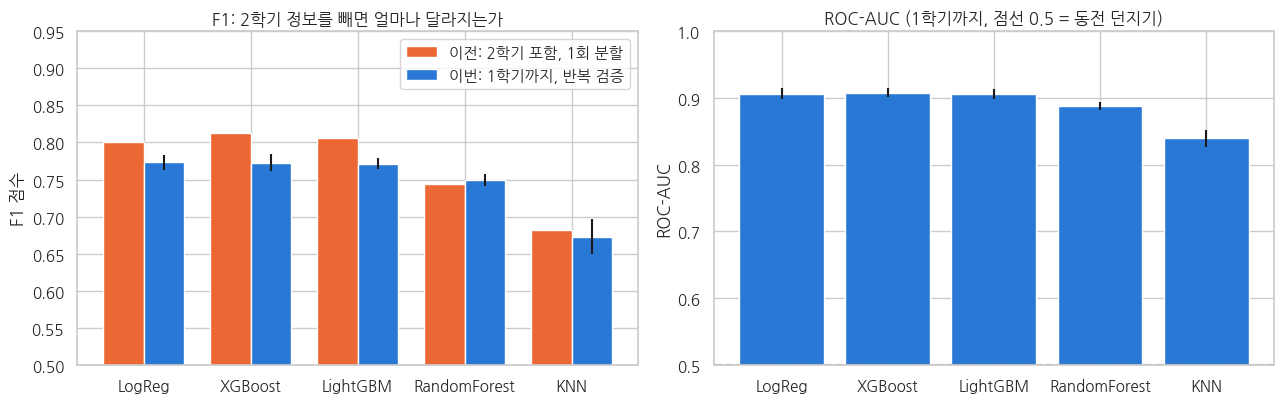

XGBoost - 로지스틱 회귀 ROC-AUC 차이: 평균 +0.0014 (표준편차 0.0037), XGBoost가 더 나은 횟수 7/10


In [4]:
# Part 1(2학기 포함, 한 번만 나눠 평가)의 F1과 나란히 비교
v1_f1 = {"LogReg": 0.8007, "XGBoost": 0.8124, "LightGBM": 0.8062, "RandomForest": 0.7436, "KNN": 0.6813}
names = list(res1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
xx = np.arange(len(names)); w = 0.38
ax[0].bar(xx - w/2, [v1_f1[n] for n in names], w, color="#eb6834", label="이전: 2학기 포함, 1회 분할")
ax[0].bar(xx + w/2, [res1[n].F1.mean() for n in names], w, yerr=[res1[n].F1.std() for n in names],
          color="#2a78d6", label="이번: 1학기까지, 반복 검증")
ax[0].set_xticks(xx); ax[0].set_xticklabels(names); ax[0].set_ylim(0.5, 0.95); ax[0].set_ylabel("F1 점수")
ax[0].set_title("F1: 2학기 정보를 빼면 얼마나 달라지는가"); ax[0].legend(loc="upper right")
ax[1].bar(names, [res1[n].ROC_AUC.mean() for n in names], yerr=[res1[n].ROC_AUC.std() for n in names], color="#2a78d6")
ax[1].axhline(0.5, color="gray", ls="--")
ax[1].set_ylim(0.5, 1.0); ax[1].set_title("ROC-AUC (1학기까지, 점선 0.5 = 동전 던지기)"); ax[1].set_ylabel("ROC-AUC")
plt.tight_layout(); plt.show()

# 성능 차이가 의미 있는가: 같은 10번의 평가에서 XGBoost와 로지스틱 회귀 비교
d = res1["XGBoost"].ROC_AUC.values - res1["LogReg"].ROC_AUC.values
print(f"XGBoost - 로지스틱 회귀 ROC-AUC 차이: 평균 {d.mean():+.4f} (표준편차 {d.std():.4f}), XGBoost가 더 나은 횟수 {(d>0).sum()}/10")

**결과 해석: 1학기 변수만 사용했을 때**

- **2학기 정보를 빼도 예측 성능이 크게 떨어지지 않았습니다.** ROC-AUC가 로지스틱 회귀 0.907, XGBoost 0.908로, 중도포기 학생과 아닌 학생 한 쌍에서 누가 중도포기할지 약 91% 맞혔습니다. 입학 시점 정보만으로는 약 0.75였으므로, 1학기 정보가 크게 기여한 것으로 판단했습니다.
- **F1은 0.77 안팎**이었습니다. Part 1의 0.80~0.81보다 0.03~0.04 낮았는데, 2학기 정보를 뺀 효과와 평가 방식을 엄격하게 바꾼 효과가 섞여 있어 정확한 하락폭으로 보지는 않았습니다. 그보다 Part 1의 점수가 현장에서 쓸 수 없는 정보를 활용한 숫자였다는 점을 중요하게 보았습니다.
- 로지스틱 회귀 기준으로, 위험하다고 지목한 학생 4명 중 약 3명(정밀도 0.75)이 실제 중도포기였고, 실제 중도포기 학생 10명 중 약 8명(재현율 0.80)을 찾아냈습니다.
- **로지스틱, XGBoost, LightGBM은 사실상 같은 성능이었습니다.** XGBoost와 로지스틱의 AUC 차이는 평균 +0.0014였고 10번 중 7번만 앞서 의미 있는 차이로 보지 않았습니다. 그래서 설명하기 쉬운 로지스틱 회귀를 써도 손해가 거의 없다고 판단했습니다. KNN은 여기서도 가장 낮았습니다.

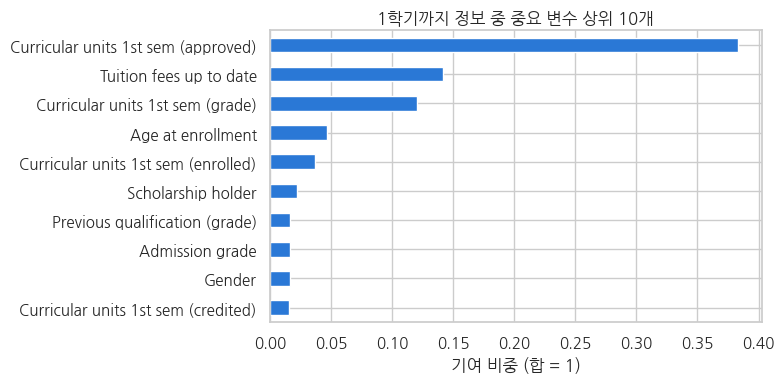

Curricular units 1st sem (approved)    0.383
Tuition fees up to date                0.142
Curricular units 1st sem (grade)       0.120
Age at enrollment                      0.047
Curricular units 1st sem (enrolled)    0.037
Scholarship holder                     0.022
Previous qualification (grade)         0.017
Admission grade                        0.016
Gender                                 0.016
Curricular units 1st sem (credited)    0.016


In [5]:
# 1학기 정보 중 무엇이 위험 신호인가: LightGBM이 가장 많이 사용한 변수 (전체 데이터로 학습)
p = build("LightGBM"); p.fit(X, y)
names_out = p["pre"].get_feature_names_out()
imp = pd.Series(p["m"].booster_.feature_importance(importance_type="gain"), index=names_out)
imp = (imp / imp.sum()).sort_values(ascending=False).head(10)
imp.index = [i.replace("num__", "").replace("cat__", "") for i in imp.index]
fig, ax = plt.subplots(figsize=(8, 4))
imp[::-1].plot(kind="barh", color="#2a78d6", ax=ax); ax.set_xlabel("기여 비중 (합 = 1)")
ax.set_title("1학기까지 정보 중 중요 변수 상위 10개"); plt.tight_layout(); plt.show()
print(imp.round(3).to_string())

**결과 해석: 1학기 정보 중 중요한 변수**

- 모델이 가장 많이 참고한 변수는 **1학기에 통과한 과목 수**(약 38%)였고, 그다음이 **등록금 납부 여부**(약 14%), **1학기 성적**(약 12%)이었습니다. 나이는 약 5%였습니다.
- 즉 "1학기에 몇 과목을 통과했는가"가 가장 유용한 조기 신호로 확인되었고, 학기 말에 상담이나 학업 지원 대상을 고를 때 우선 볼 기준으로 판단했습니다.
- 이 순위는 모델이 정보를 활용한 정도이며 중도포기의 원인은 아닙니다. 또 등록금 납부 여부는 데이터에 측정 시점이 나와 있지 않아, 1학기 말까지 실제로 알 수 있는 정보인지는 확인이 필요했습니다.

## 2-2. SMOTE 적용: 불균형을 인위적으로 보정하면 더 잘 찾는가

**SMOTE**는 소수 클래스(여기서는 중도포기 학생)의 기존 사례들 사이를 이어 비슷한 가상의 사례를 새로 만들어 학습 데이터에 더하는 방법입니다. 중도포기 학생이 적어 모델이 놓치는 문제를 줄이려는 목적으로 시도했습니다.

**진행하면서 주의한 점**
- SMOTE는 **학습용 데이터에만** 적용했습니다. 평가용 데이터까지 섞이면 가상의 사례로 점수를 매기게 되므로, 교차 검증의 각 학습 조각 안에서만 SMOTE가 적용되도록 파이프라인을 구성했습니다.
- 비교 대상은 세 가지였습니다: ① 보정 없음, ② 가중치 보정(`class_weight`, 중도포기 학생을 틀릴 때 더 큰 벌점), ③ SMOTE.
- 점수는 두 종류로 보았습니다. 기준 확률(0.5)에서의 정밀도·재현율은 보정 방식에 따라 크게 움직이지만, ROC-AUC와 PR-AUC는 기준과 상관없는 **순위를 매기는 능력**이라 실제 성능 차이를 보여 줍니다.

In [6]:
def lr_plain():  return LogisticRegression(C=0.1, max_iter=3000)
def lr_weight(): return LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced")
def lgb_plain(): return LGBMClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                       random_state=SEED, verbose=-1, n_jobs=2)
def lgb_weight():return LGBMClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                       class_weight="balanced", random_state=SEED, verbose=-1, n_jobs=2)

def strat(est_fn, smote, scale):
    steps = [("pre", make_pre(scale))]
    if smote: steps.append(("smote", SMOTE(random_state=SEED)))     # 학습 조각 안에서만 작동
    steps.append(("m", est_fn()))
    return (ImbPipeline if smote else Pipeline)(steps)

settings = {
 "로지스틱 | 보정 없음":  lambda: strat(lr_plain,  False, True),
 "로지스틱 | 가중치":     lambda: strat(lr_weight, False, True),
 "로지스틱 | SMOTE":      lambda: strat(lr_plain,  True,  True),
 "LightGBM | 보정 없음":  lambda: strat(lgb_plain,  False, False),
 "LightGBM | 가중치":     lambda: strat(lgb_weight, False, False),
 "LightGBM | SMOTE":      lambda: strat(lgb_plain,  True,  False),
}
res2 = {k: cv_binary(f, X, y) for k, f in settings.items()}
print("기준 확률 0.5에서의 점수와 순위 능력, 10회 평가의 평균 ± 표준편차")
print(summarize(res2).to_string())

기준 확률 0.5에서의 점수와 순위 능력, 10회 평가의 평균 ± 표준편차
                             F1            정밀도            재현율        ROC_AUC         PR_AUC
로지스틱 | 보정 없음      0.758 ± 0.023  0.847 ± 0.020  0.687 ± 0.033  0.906 ± 0.008  0.861 ± 0.013
로지스틱 | 가중치        0.771 ± 0.012  0.748 ± 0.016  0.797 ± 0.018  0.906 ± 0.008  0.860 ± 0.012
로지스틱 | SMOTE      0.769 ± 0.013  0.745 ± 0.019  0.796 ± 0.017  0.906 ± 0.008  0.859 ± 0.012
LightGBM | 보정 없음  0.763 ± 0.015  0.844 ± 0.013  0.697 ± 0.026  0.906 ± 0.007  0.863 ± 0.008
LightGBM | 가중치    0.771 ± 0.007  0.755 ± 0.013  0.789 ± 0.018  0.906 ± 0.008  0.862 ± 0.010
LightGBM | SMOTE  0.768 ± 0.014  0.836 ± 0.018  0.711 ± 0.024  0.906 ± 0.007  0.863 ± 0.009


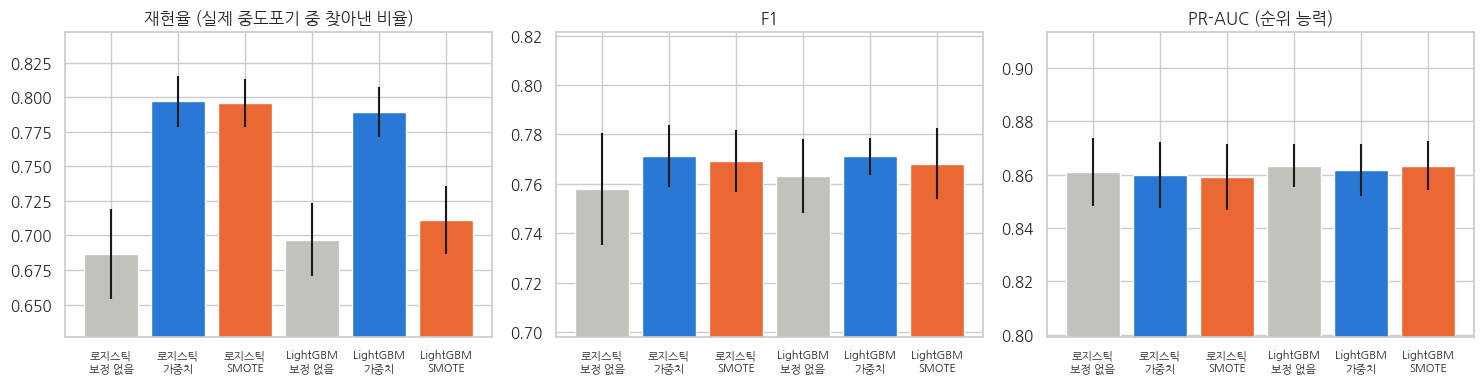

회색 = 보정 없음, 파랑 = 가중치, 주황 = SMOTE  (막대 그래프의 세로축은 일부 구간만 보여 주므로 차이가 실제보다 커 보입니다)


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
cols = ["#c2c1bb", "#2a78d6", "#eb6834"] * 2
for a, m, t in zip(ax, ["재현율", "F1", "PR_AUC"], ["재현율 (실제 중도포기 중 찾아낸 비율)", "F1", "PR-AUC (순위 능력)"]):
    vals = [res2[k][m].mean() for k in res2]; errs = [res2[k][m].std() for k in res2]
    a.bar(range(6), vals, yerr=errs, color=cols); a.set_xticks(range(6))
    a.set_xticklabels([k.replace(" | ", "\n") for k in res2], fontsize=8); a.set_title(t)
    a.set_ylim(min(vals) - 0.06, max(vals) + 0.05)
plt.tight_layout(); plt.show()
print("회색 = 보정 없음, 파랑 = 가중치, 주황 = SMOTE  (막대 그래프의 세로축은 일부 구간만 보여 주므로 차이가 실제보다 커 보입니다)")

**결과 해석: SMOTE의 효과**

- **보정을 하지 않으면** 정밀도는 높았지만(0.85) 재현율이 낮았습니다(0.69). 중도포기 학생이 적어 모델이 "중도포기"로 지목하는 데 보수적이었기 때문으로 보았습니다.
- **가중치 보정이나 SMOTE를 적용하면** 재현율이 0.80 안팎으로 올라갔지만 정밀도는 0.75로 내려갔습니다. 더 많이 찾는 대신 잘못 지목하는 경우도 늘었습니다.
- 그러나 **순위를 매기는 능력(ROC-AUC 0.906, PR-AUC 약 0.86)은 방법과 상관없이 같았습니다.** 모델 자체가 나아진 것이 아니라 "중도포기로 지목하는 기준"만 이동한 것으로 판단했습니다.
- SMOTE와 가중치 보정을 비교하면, 로지스틱에서는 재현율이 0.796 대 0.797로 사실상 같았고 LightGBM에서는 SMOTE(0.711)가 가중치(0.789)보다 오히려 낮았습니다. **이 데이터에서는 SMOTE가 추가로 주는 이점이 없는 것으로 확인되었고**, 더 간단한 가중치 보정이나 기준 확률 조정으로 충분하다고 결론지었습니다.
- 둘 중 무엇을 택할지는 현실의 비용에 달려 있다고 보았습니다. 상담 인력이 충분하면 재현율을, 부족하면 정밀도를 우선하는 식이며, 이 판단을 Part 4의 "한정된 자원 배분" 분석으로 이어 갔습니다.
- 한계: 변수 대부분이 원-핫 인코딩된 범주형이라 SMOTE가 만든 사례에 소수점 값이 생겼습니다. 범주형에 맞춘 SMOTENC로도 확인할 수 있었지만, 순위 능력이 모든 방식에서 같았기 때문에 결론이 크게 바뀌지 않을 것으로 판단했습니다.

## 2-3. 다중 클래스: 중도포기 / 재학 중 / 졸업을 모두 예측

앞에서는 "재학 중(Enrolled)"을 "중도포기 아님"에 합쳐 두 그룹으로만 보았습니다. 하지만 아직 졸업하지 못하고 재학 중인 학생은 졸업생과 상황이 다를 수 있어, 세 그룹을 모두 예측해 모델이 어느 구분을 어려워하는지 확인했습니다.

**사용한 지표**
- **정확도**: 세 그룹 전체에서 맞힌 비율 (졸업이 약 50%라 모두 "졸업"으로 답해도 50%)
- **Macro F1**: 세 그룹의 F1을 같은 비중으로 평균한 값. 적은 그룹도 동등하게 반영
- **그룹별 재현율**: 각 그룹의 실제 학생 중 맞힌 비율

In [8]:
def build3(name):
    if name == "LogReg":
        return Pipeline([("pre", make_pre()), ("m", LogisticRegression(C=0.1, max_iter=4000, class_weight="balanced"))])
    if name == "RandomForest":
        return Pipeline([("pre", make_pre(False)), ("m", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                         class_weight="balanced_subsample", random_state=SEED, n_jobs=2))])
    if name == "LightGBM":
        return Pipeline([("pre", make_pre(False)), ("m", LGBMClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, class_weight="balanced", random_state=SEED, verbose=-1, n_jobs=2))])
    if name == "XGBoost":   # XGBoost는 class_weight가 없어 샘플 가중치로 균형을 맞춤
        return Pipeline([("pre", make_pre(False)), ("m", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8, objective="multi:softprob", eval_metric="mlogloss",
                         random_state=SEED, n_jobs=2))])

LAB = ["중도포기", "재학 중", "졸업"]
def cv_multi(name):
    rows = []
    for tr, te in cv.split(X, y3):
        p = build3(name)
        if name == "XGBoost": p.fit(X.iloc[tr], y3.iloc[tr], m__sample_weight=compute_sample_weight("balanced", y3.iloc[tr]))
        else: p.fit(X.iloc[tr], y3.iloc[tr])
        pred = p.predict(X.iloc[te]); t = y3.iloc[te]
        rc = recall_score(t, pred, average=None)
        rows.append({"정확도": accuracy_score(t, pred), "Macro_F1": f1_score(t, pred, average="macro"),
                     "재현율_중도포기": rc[0], "재현율_재학중": rc[1], "재현율_졸업": rc[2]})
    return pd.DataFrame(rows)

res3 = {n: cv_multi(n) for n in ["LogReg", "RandomForest", "LightGBM", "XGBoost"]}
print("3분류 (1학기 변수만), 10회 평가의 평균 ± 표준편차")
print(summarize(res3).to_string())
print(f"\n참고: 무조건 '졸업'이라고만 답할 때의 정확도 = {(y3 == 2).mean():.1%}")

3분류 (1학기 변수만), 10회 평가의 평균 ± 표준편차
                        정확도       Macro_F1       재현율_중도포기        재현율_재학중         재현율_졸업
LogReg        0.725 ± 0.012  0.683 ± 0.013  0.698 ± 0.013  0.575 ± 0.035  0.796 ± 0.016
RandomForest  0.723 ± 0.014  0.677 ± 0.015  0.687 ± 0.027  0.549 ± 0.035  0.808 ± 0.017
LightGBM      0.731 ± 0.012  0.691 ± 0.013  0.694 ± 0.021  0.603 ± 0.038  0.801 ± 0.015
XGBoost       0.732 ± 0.015  0.693 ± 0.017  0.693 ± 0.022  0.610 ± 0.039  0.800 ± 0.018

참고: 무조건 '졸업'이라고만 답할 때의 정확도 = 49.9%


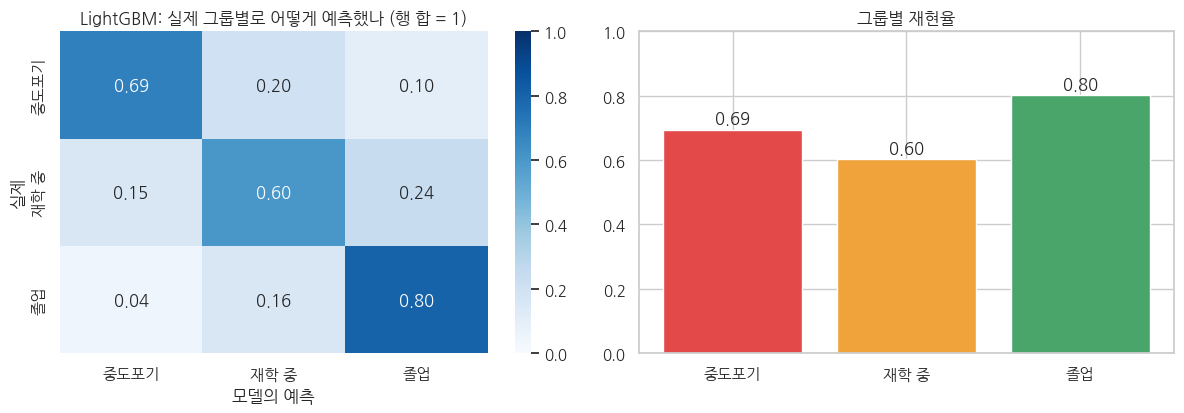

3분류 모델의 '중도포기 확률'로 계산한 ROC-AUC = 0.903  (이진 모델 LightGBM 평균 0.906)


In [9]:
# 혼동 행렬: 한 번씩 평가한 예측을 모아서(5조각) 어느 그룹을 어느 그룹으로 착각하는지 확인
best = "LightGBM"
oof = np.zeros(len(df), dtype=int); oof_prob = np.zeros((len(df), 3))
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y3):
    p = build3(best); p.fit(X.iloc[tr], y3.iloc[tr])
    oof_prob[te] = p.predict_proba(X.iloc[te]); oof[te] = oof_prob[te].argmax(1)
cm = confusion_matrix(y3, oof, normalize="true")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LAB, yticklabels=LAB, ax=ax[0], vmin=0, vmax=1)
ax[0].set_xlabel("모델의 예측"); ax[0].set_ylabel("실제"); ax[0].set_title(f"{best}: 실제 그룹별로 어떻게 예측했나 (행 합 = 1)")
rec = res3[best][["재현율_중도포기", "재현율_재학중", "재현율_졸업"]].mean().values
ax[1].bar(LAB, rec, color=["#e34948", "#f0a23b", "#4aa56b"]); ax[1].set_ylim(0, 1); ax[1].set_title("그룹별 재현율")
for i, v in enumerate(rec): ax[1].text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.show()

# 세 갈래 모델에서 '중도포기 확률'만 뽑아 이진 모델과 비교
auc_multi = roc_auc_score((y3 == 0).astype(int), oof_prob[:, 0])
print(f"3분류 모델의 '중도포기 확률'로 계산한 ROC-AUC = {auc_multi:.3f}  (이진 모델 LightGBM 평균 {res1['LightGBM'].ROC_AUC.mean():.3f})")

**결과 해석: 세 그룹 예측**

- 전체 정확도는 약 73%로, 모두 "졸업"으로 답할 때의 50%보다 훨씬 높았습니다. Macro F1은 0.68~0.69였고 네 모델의 차이는 매우 작았습니다.
- 그룹별로는 **졸업 80%, 중도포기 약 69%, 재학 중 약 60%**를 맞혔습니다. 재학 중 학생은 졸업으로 24%, 중도포기로 15% 잘못 분류되었습니다.
- 재학 중 구분이 가장 어려웠던 것은 자연스러운 결과로 보았습니다. 아직 결과가 정해지지 않은 중간 상태라, 1학기 이수 과목 수도 중도포기(평균 2.6개)와 졸업(평균 6.2개) 사이(평균 4.3개)에 있었습니다.
- 세 그룹 모델에서 "중도포기 확률"만 따로 평가해도 ROC-AUC가 0.903으로 이진 모델(0.906)과 거의 같았습니다. 세 그룹으로 넓혀도 중도포기를 구별하는 능력은 유지되는 것으로 확인되었습니다.
- 활용 면에서는 위험·안전 학생을 가르는 것 외에 "중간 위험군"을 따로 두고 관찰하는 방식도 가능하다고 보았습니다. 다만 "재학 중"은 관찰이 끝난 시점의 상태일 뿐 최종 결과가 아니어서, 이후 졸업이나 중도포기로 바뀔 수 있다는 점을 해석에 반영했습니다.

## 2-4. 종합 정리

### 세 가지 시도의 결과

| 시도 | 결과 | 의미 |
|---|---|---|
| 1학기 변수만 사용 | ROC-AUC 약 0.91, F1 약 0.77 (로지스틱·XGBoost·LightGBM 비슷) | 2학기 정보 없이도 1학기 말에 쓸 수 있는 예측이 가능했고, 설명하기 쉬운 로지스틱으로 충분하다고 판단했습니다. |
| SMOTE 적용 | 순위 능력 변화 없음, 재현율은 가중치 보정과 비슷하거나 낮음 | 이 데이터에서는 SMOTE의 추가 이점이 없었고, 기준 확률이나 가중치 조정으로 충분했습니다. |
| 3분류 | 정확도 약 73%, Macro F1 약 0.69, 재학 중 재현율 약 0.60 | 재학 중은 중간 상태라 구분이 어려웠지만, 중도포기 식별력은 유지되었습니다. |

### 남은 한계와 다음 단계

- **한 대학, 한 시기의 데이터**였습니다. 외부 데이터로 일반화를 확인하는 작업은 진행하지 못했습니다.
- **등록금·장학금 변수의 측정 시점**이 불분명해, 1학기 말 정보로 쓸 수 있는지 확인이 필요했습니다.
- **예측을 개입으로 연결하는 단계**가 남아 있었습니다. 상담 인력이나 예산이 정해져 있을 때 누구에게 먼저 개입할지를 Part 4에서 시나리오로 비교했습니다.
- 이 분석의 숫자는 "예측이 얼마나 맞는가"를 보여 줄 뿐, "개입하면 중도포기가 줄어든다"는 의미는 아닙니다.

# Part 3. 중도포기 학생의 유형: 군집 분석(비지도학습)

### 중도포기 학생 유형 분석

앞선 분석은 "누가 중도포기할 가능성이 높은가"를 맞히는 **지도학습**이었습니다. 여기서는 정답(중도포기 여부)을 쓰지 않고 **중도포기한 학생 1,421명을 비슷한 특성끼리 묶어**, 중도포기 학생이 모두 같은 모습인지 서로 다른 유형이 있는지 살펴보았습니다. 그리고 앞의 예측 모델이 어떤 유형을 잘 찾고 어떤 유형을 놓치는지도 확인했습니다.

사용한 정보는 **1학기 말까지 알 수 있는 정보**(입학 시점 + 재정 + 1학기)였습니다.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings, os
warnings.filterwarnings("ignore")
from matplotlib import font_manager
_ng = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
if os.path.exists(_ng): font_manager.fontManager.addfont(_ng)
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"]:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
sns.set(style="whitegrid", font=plt.rcParams["font.family"][0])

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
SEED = 789

df = pd.read_csv("data.csv", sep=";")
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={"Nacionality": "Nationality"})
df["y"] = (df["Target"] == "Dropout").astype(int)

app = ["Marital status","Application mode","Application order","Course","Daytime/evening attendance","Previous qualification",
       "Previous qualification (grade)","Nationality","Mother's qualification","Father's qualification","Mother's occupation",
       "Father's occupation","Admission grade","Displaced","Educational special needs","Gender","Age at enrollment","International",
       "Unemployment rate","Inflation rate","GDP"]
fin  = ["Tuition fees up to date","Debtor","Scholarship holder"]
sem1 = [c for c in df.columns if "1st sem" in c]
FEAT = app + fin + sem1                          # 1학기 말까지 알 수 있는 정보 (2학기 변수 제외)
cat_cols = ["Marital status","Application mode","Course","Previous qualification","Nationality",
            "Mother's qualification","Father's qualification","Mother's occupation","Father's occupation"]
X, y = df[FEAT], df["y"]
N = len(df); print("학생 수:", N, "| 중도포기:", int(y.sum()), f"({y.mean():.1%})")

학생 수: 4424 | 중도포기: 1421 (32.1%)


In [2]:
def make_pipe():
    cats = [c for c in FEAT if c in cat_cols]; nums = [c for c in FEAT if c not in cat_cols]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), cats),
        ("num", StandardScaler(), nums)])
    return Pipeline([("pre", pre), ("m", LogisticRegression(C=0.1, max_iter=3000))])   # 보정 없는 로지스틱: 확률을 그대로 해석하기 위함

# 각 학생에 대해 "그 학생을 학습에 쓰지 않은 모델"이 낸 위험 확률을 구함 (5조각 x 3회 평균)
prob = np.zeros(N)
for rep in range(3):
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED + rep).split(X, y):
        p = make_pipe().fit(X.iloc[tr], y.iloc[tr]); prob[te] += p.predict_proba(X.iloc[te])[:, 1] / 3
df["risk"] = prob
order_model = np.argsort(-df["risk"].values)          # 위험 확률이 높은 순서
yv = y.values
print(f"위험 확률 ROC-AUC = {roc_auc_score(y, prob):.3f}")
print(f"위험 확률 평균 {prob.mean():.3f} vs 실제 중도포기 비율 {y.mean():.3f}  (비슷하면 확률이 잘 보정된 것)")

위험 확률 ROC-AUC = 0.906
위험 확률 평균 0.322 vs 실제 중도포기 비율 0.321  (비슷하면 확률이 잘 보정된 것)


## 3-1. 중도포기 학생을 유형으로 나누기

정답 없이 중도포기한 1,421명을 비슷한 특성끼리 묶는 **군집 분석(비지도학습)**을 진행했습니다. 목적은 중도포기 학생이 모두 같은 모습인지, 서로 다른 유형이 있는지 확인하는 것이었습니다.

**주의한 점**: 군집은 데이터를 나누는 하나의 방식일 뿐, 그런 유형이 실제로 존재한다는 증명은 아닙니다. 그래서 (1) 군집 개수를 점수로 확인하고, (2) 데이터를 다시 뽑아도 같은 군집이 나오는지(안정성)를 점검한 뒤 해석했습니다.

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

dd = df[df["y"] == 1].copy()
cl_cols = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)", "Curricular units 1st sem (enrolled)",
           "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (without evaluations)",
           "Tuition fees up to date", "Debtor", "Scholarship holder", "Age at enrollment", "Admission grade", "Gender"]
Z = StandardScaler().fit_transform(dd[cl_cols])

print("군집 수별 점수 (실루엣: 클수록 군집이 뚜렷함, 1에 가까울수록 좋고 0.25 미만이면 약한 구조)")
for k in range(2, 8):
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z)
    print(f"  k={k}: 실루엣 {silhouette_score(Z, km.labels_):.3f}")

군집 수별 점수 (실루엣: 클수록 군집이 뚜렷함, 1에 가까울수록 좋고 0.25 미만이면 약한 구조)
  k=2: 실루엣 0.196


  k=3: 실루엣 0.216
  k=4: 실루엣 0.215


  k=5: 실루엣 0.224
  k=6: 실루엣 0.194


  k=7: 실루엣 0.187


In [4]:
K = 4                                           # 점수와 해석 가능성을 함께 고려해 정함 (아래 안정성 점검 참고)
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
# 군집 번호는 실행마다 달라질 수 있어서, 1학기 통과 과목이 적은 순서로 번호를 다시 매김
_order = pd.Series(dd["Curricular units 1st sem (approved)"].values).groupby(km.labels_).mean().sort_values().index
_remap = {old: new for new, old in enumerate(_order)}
dd["cluster"] = [ _remap[l] for l in km.labels_ ]
km.labels_ = dd["cluster"].values

# 안정성: 학생을 80%만 무작위로 뽑아 다시 군집했을 때 원래 군집과 얼마나 같은가 (1에 가까울수록 안정)
rng = np.random.RandomState(SEED); aris = []
for _ in range(30):
    idx = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    sub = KMeans(K, n_init=10, random_state=int(rng.randint(10**6))).fit(Z[idx])
    aris.append(adjusted_rand_score(km.labels_[idx], sub.labels_))
print(f"k={K} 군집 안정성 (ARI) 평균 {np.mean(aris):.2f}, 최저 {np.min(aris):.2f}")

prof = dd.groupby("cluster").agg(
    학생수=("y", "size"),
    통과과목=("Curricular units 1st sem (approved)", "mean"),
    성적=("Curricular units 1st sem (grade)", "mean"),
    신청과목=("Curricular units 1st sem (enrolled)", "mean"),
    시험미응시=("Curricular units 1st sem (without evaluations)", "mean"),
    등록금납부=("Tuition fees up to date", "mean"),
    채무=("Debtor", "mean"),
    장학금=("Scholarship holder", "mean"),
    나이=("Age at enrollment", "mean"),
    입학성적=("Admission grade", "mean"),
    남성비율=("Gender", "mean")).round(2)
prof["비중"] = (prof["학생수"] / len(dd)).map("{:.0%}".format)
# 특징으로 이름 붙이기 (규칙 기반): 통과 과목이 가장 적음 / 채무 비율이 가장 높음 / 장학금 비율이 가장 높음 / 나머지
names = {}
names[prof["통과과목"].idxmin()] = "학기 중 이탈형"
names[prof["채무"].idxmax()] = "채무·등록금 미납형"
for c in prof.sort_values("장학금", ascending=False).index:
    if c not in names: names[c] = "장학금 수혜형"; break
for c in prof.index:
    if c not in names: names[c] = "학업 중간형"
prof.insert(0, "이름", [names[c] for c in prof.index])
print(prof.to_string())

k=4 군집 안정성 (ARI) 평균 0.88, 최저 0.61
                 이름  학생수  통과과목     성적  신청과목  시험미응시  등록금납부    채무  장학금     나이    입학성적  남성비율   비중
cluster                                                                                       
0          학기 중 이탈형  460  0.02   0.14  4.73   0.23   0.73  0.05  0.0  26.73  124.86  0.53  32%
1        채무·등록금 미납형  253  2.83   8.52  6.15   0.22   0.24  1.00  0.0  27.51  125.38  0.49  18%
2           장학금 수혜형  134  3.28   9.10  5.37   0.11   0.79  0.23  1.0  22.22  125.46  0.34   9%
3            학업 중간형  574  4.29  11.97  6.66   0.17   0.81  0.01  0.0  25.80  124.75  0.50  40%


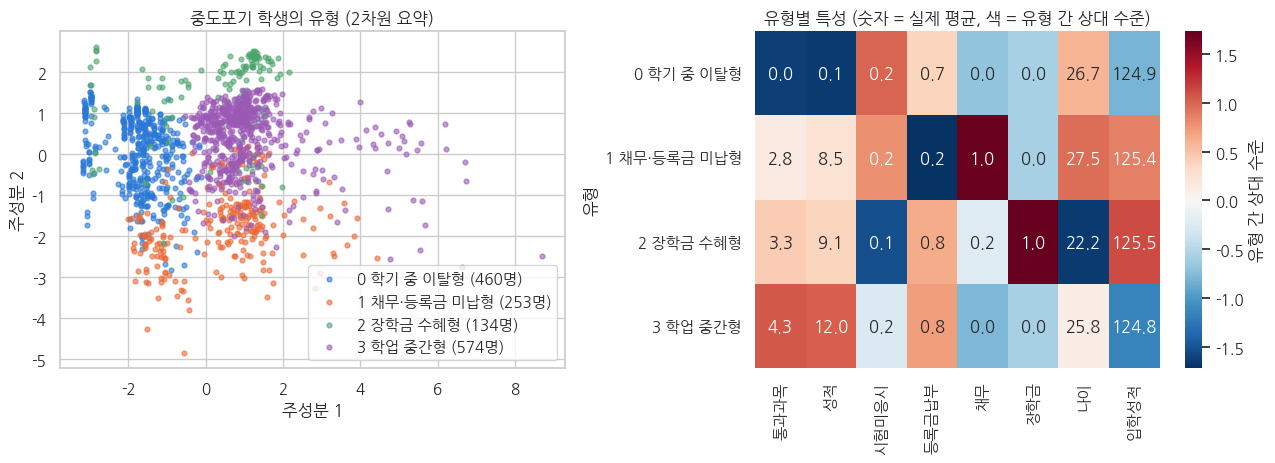

In [5]:
# 군집을 2차원 그림으로 (주성분 분석으로 축소; 점의 위치는 요약일 뿐)
pc = PCA(2, random_state=SEED).fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
pal = ["#2a78d6", "#eb6834", "#4aa56b", "#9b59b6", "#c0392b", "#7f8c8d"]
for c in range(K):
    m = dd["cluster"].values == c
    ax[0].scatter(pc[m, 0], pc[m, 1], s=12, alpha=0.6, color=pal[c], label=f"{c} {names[c]} ({m.sum()}명)")
ax[0].set_title("중도포기 학생의 유형 (2차원 요약)"); ax[0].legend(); ax[0].set_xlabel("주성분 1"); ax[0].set_ylabel("주성분 2")

# 핵심 특성을 유형별로 비교 (표준화 값, 전체 중도포기 학생 평균 대비)
show = ["통과과목", "성적", "시험미응시", "등록금납부", "채무", "장학금", "나이", "입학성적"]
zz = (prof[show] - prof[show].mean()) / prof[show].std(ddof=0)
sns.heatmap(zz, annot=prof[show].round(1), fmt="", cmap="RdBu_r", center=0, ax=ax[1], cbar_kws={"label": "유형 간 상대 수준"})
ax[1].set_title("유형별 특성 (숫자 = 실제 평균, 색 = 유형 간 상대 수준)"); ax[1].set_ylabel("유형")
ax[1].set_yticklabels([f"{c} {names[c]}" for c in prof.index], rotation=0)
plt.tight_layout(); plt.show()

**결과 해석: 중도포기 학생의 네 가지 유형**

- **학기 중 이탈형 (32%, 460명)**: 1학기에 평균 4.7과목을 신청했지만 통과한 과목이 사실상 0개였습니다. 등록금은 대부분(73%) 납부한 상태였습니다. 학기 도중에 학업을 사실상 중단한 학생들로 보았습니다.
- **채무·등록금 미납형 (18%, 253명)**: 전원이 채무 상태였고 등록금 납부율이 24%로 낮았습니다. 통과 과목은 평균 2.8개였습니다. 재정 어려움과 학업 부진이 함께 나타난 유형이었습니다.
- **장학금 수혜형 (9%, 134명)**: 전원이 장학금을 받았고 평균 나이가 22세로 다른 유형(약 26~28세)보다 어렸습니다. 통과 과목은 3.3개, 성적은 9.1점이었습니다.
- **학업 중간형 (40%, 574명)**: 등록금을 정상 납부했고 채무가 없었으며, 통과 과목 4.3개, 성적 12.0점이었습니다. 졸업생(평균 통과 6.2개)보다는 낮지만 중도포기 학생 평균(약 2.6개)보다는 높아, 학업 지표만으로는 눈에 띄지 않는 학생들이었습니다.
- 주의: 실루엣 점수(같은 군집끼리 가깝고 다른 군집과 먼 정도)가 0.2 안팎(0.25 미만)이라 **유형 사이의 경계가 뚜렷하지는 않았습니다.** 학생의 80%만 무작위로 뽑아 다시 군집해도 비슷한 결과가 나오는 것(ARI 평균 0.88)은 확인했지만, 이 네 유형은 설명을 위한 구분이지 실제로 구별되는 집단이라는 증명은 아니라고 판단했습니다. 군집 번호와 세부 수치는 무작위 초기값에 따라 조금 달라질 수 있습니다.

## 3-2. 예측 모델이 놓치는 유형

예측 모델이 위험 확률이 높다고 판단한 **상위 20%** 학생에 각 유형의 중도포기 학생이 얼마나 포함되는지 확인했습니다. 이 값이 낮은 유형은 모델이 잘 찾지 못하는 유형(사각지대)으로 보았습니다.

위험 확률 상위 20% 기준, 유형별로 실제 중도포기 학생이 포함된 비율
                 이름  학생수  상위20퍼_포함_비율  위험 확률 평균
cluster                                        
0          학기 중 이탈형  460         0.88      0.87
1        채무·등록금 미납형  253         0.79      0.83
2           장학금 수혜형  134         0.32      0.41
3            학업 중간형  574         0.29      0.50

전체 중도포기 학생 평균 포함 비율 = 0.57


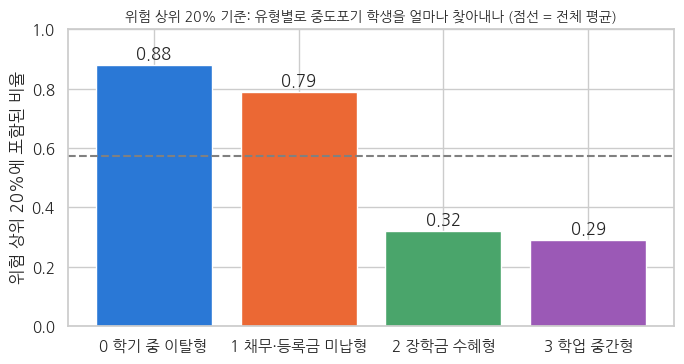

In [6]:
k20 = int(0.2 * N)
flag = np.zeros(N, dtype=bool); flag[order_model[:k20]] = True
dd["flagged20"] = flag[dd.index.values]
miss = dd.groupby("cluster").agg(학생수=("y", "size"), 상위20퍼_포함_비율=("flagged20", "mean")).round(2)
miss["위험 확률 평균"] = dd.groupby("cluster")["risk"].mean().round(2)
miss.insert(0, "이름", [names[c] for c in miss.index])
print("위험 확률 상위 20% 기준, 유형별로 실제 중도포기 학생이 포함된 비율")
print(miss.to_string())
print(f"\n전체 중도포기 학생 평균 포함 비율 = {dd['flagged20'].mean():.2f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar([f"{c} {names[c]}" for c in miss.index], miss["상위20퍼_포함_비율"], color=pal[:K])
ax.axhline(dd["flagged20"].mean(), color="gray", ls="--"); ax.set_ylim(0, 1)
ax.set_ylabel("위험 상위 20%에 포함된 비율"); ax.set_title("위험 상위 20% 기준: 유형별로 중도포기 학생을 얼마나 찾아내나 (점선 = 전체 평균)", fontsize=10)
for i, v in enumerate(miss["상위20퍼_포함_비율"]): ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.show()

**결과 해석: 모델이 놓치는 유형**

- 위험 확률 상위 20%에 포함된 비율은 **학기 중 이탈형 88%, 채무·등록금 미납형 79%, 장학금 수혜형 32%, 학업 중간형 29%**였습니다. 전체 평균은 57%였습니다.
- 모델이 학업 부진과 등록금 같은 뚜렷한 신호를 크게 반영하기 때문에, 그런 신호가 분명한 두 유형은 잘 찾았고 **신호가 약한 두 유형(전체 중도포기 학생의 약 절반)은 상당수를 놓친 것으로 확인되었습니다.**
- 이 데이터에는 학업 중간형이 왜 학교를 떠났는지 설명할 변수(개인 사정, 진로 변경, 만족도 등)가 없었습니다. 그래서 이 유형은 현재 정보만으로는 포착하기 어렵고, 상담이나 설문 같은 다른 정보가 필요하다는 데까지만 결론을 내렸습니다.

## 3-3. 정리

| 분석 | 결과 | 의미 |
|---|---|---|
| 중도포기 유형 | 학기 중 이탈 32%, 채무·미납 18%, 장학금 수혜 9%, 학업 중간 40% | 중도포기 학생을 하나의 모습으로 설명하기 어려웠습니다. |
| 모델의 사각지대 | 장학금 수혜형·학업 중간형은 위험 상위 20%에 29~32%만 포함 | 학업·재정 신호가 약한 학생은 현재 변수로 놓치는 것으로 확인되었습니다. |

### 분석의 범위와 한계

- **확인한 것**: 중도포기 학생을 네 가지 유형으로 나눠 볼 수 있다는 점, 예측 모델이 어떤 유형을 잘 찾고 어떤 유형을 놓치는지
- **확인할 수 없었던 것**: 각 유형이 왜 학교를 떠났는지(이유를 설명할 변수가 없음), 유형별로 어떤 지원이 효과적인지(개입 기록이 없음)
- 유형 구분은 설명을 위한 것이며, 실루엣 점수가 낮아 경계가 뚜렷하지 않았습니다.
- 한 대학, 한 시기의 데이터였고, 등록금·장학금 변수의 측정 시점이 불분명했습니다.

# Part 4. 상담 인원이 정해져 있을 때 누구에게 먼저 연락할 것인가

현실에서는 상담 인력이 한정되어 있어 위험하다고 판단된 학생을 모두 만날 수 없습니다. 그래서 **위험 확률이 높은 순서로 K%의 학생에게만 연락한다**고 가정하고 두 가지를 확인했습니다.

- **정밀도**: 연락한 학생 중 실제로 중도포기한 학생의 비율 (불필요한 연락을 얼마나 줄이는가)
- **재현율**: 전체 중도포기 학생 중 연락이 닿은 학생의 비율 (얼마나 놓치지 않는가)

비교 기준으로, 모델 없이 학교가 바로 쓸 수 있는 단순 규칙도 같은 방식으로 평가했습니다. 규칙은 "1학기 이수 과목이 가장 적은 학생부터, 같으면 성적이 낮은 학생부터 연락"이었습니다. 위험 확률은 Part 3과 같은 값(각 학생을 학습에 쓰지 않은 모델이 낸 확률)을 사용했습니다.

**주의**: 이 비교는 예측이 얼마나 맞는지를 보여 줄 뿐입니다. 연락했을 때 중도포기가 실제로 줄어드는지는 이 데이터로 확인할 수 없었습니다. 상담 인원이 한정된 상황 자체도 실제 데이터가 아니라 가정한 시나리오입니다.

In [7]:
P = yv.sum(); base = yv.mean()
rule_score = -(df["Curricular units 1st sem (approved)"].values * 100 + df["Curricular units 1st sem (grade)"].values)
order_rule = np.argsort(-rule_score)           # 이수 학점이 적고 성적이 낮은 학생부터

rows = []
for k in [0.05, 0.10, 0.20, 0.30, 0.40]:
    n = int(round(k * N))
    for name, order in [("모델(로지스틱)", order_model), ("단순 규칙(이수 학점 적은 순)", order_rule)]:
        hit = yv[order[:n]].sum()
        rows.append({"연락 범위": f"상위 {int(k*100)}%", "방법": name, "연락 인원": n,
                     "정밀도": round(hit / n, 3), "재현율": round(hit / P, 3), "무작위 대비 배수": round((hit / n) / base, 2)})
topk = pd.DataFrame(rows)
print(f"무작위로 연락하면 정밀도는 전체 중도포기 비율 {base:.1%}와 같습니다.")
print(topk.to_string(index=False))

무작위로 연락하면 정밀도는 전체 중도포기 비율 32.1%와 같습니다.
 연락 범위                방법  연락 인원   정밀도   재현율  무작위 대비 배수
 상위 5%          모델(로지스틱)    221 0.977 0.152       3.04
 상위 5% 단순 규칙(이수 학점 적은 순)    221 0.787 0.122       2.45
상위 10%          모델(로지스틱)    442 0.980 0.305       3.05
상위 10% 단순 규칙(이수 학점 적은 순)    442 0.801 0.249       2.49
상위 20%          모델(로지스틱)    885 0.922 0.574       2.87
상위 20% 단순 규칙(이수 학점 적은 순)    885 0.776 0.483       2.42
상위 30%          모델(로지스틱)   1327 0.800 0.747       2.49
상위 30% 단순 규칙(이수 학점 적은 순)   1327 0.708 0.661       2.20
상위 40%          모델(로지스틱)   1770 0.685 0.854       2.13
상위 40% 단순 규칙(이수 학점 적은 순)   1770 0.611 0.761       1.90


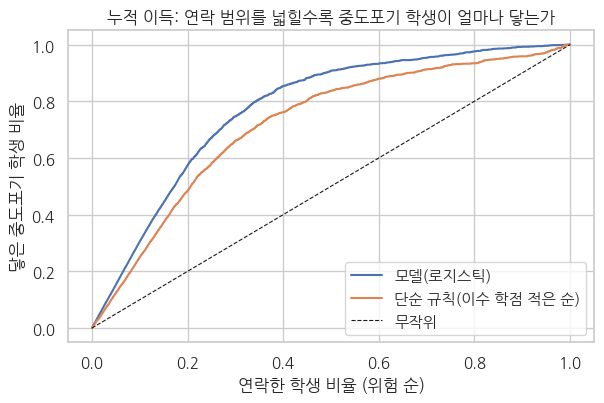

In [8]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for name, order in [("모델(로지스틱)", order_model), ("단순 규칙(이수 학점 적은 순)", order_rule)]:
    cum = np.concatenate([[0], np.cumsum(yv[order])]) / P
    ax.plot(np.arange(N + 1) / N, cum, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=.8, label="무작위")
ax.set_xlabel("연락한 학생 비율 (위험 순)"); ax.set_ylabel("닿은 중도포기 학생 비율")
ax.set_title("누적 이득: 연락 범위를 넓힐수록 중도포기 학생이 얼마나 닿는가"); ax.legend(); plt.tight_layout(); plt.show()

### 결과 해석: 연락 인원이 한정될 때

- 위험 확률 상위 10%(442명)에 연락하면 98.0%가 실제 중도포기 학생이었고, 전체 중도포기 학생의 30.5%를 포착했습니다.
- 상위 20%(885명)는 정밀도 92.2%, 재현율 57.4%였습니다. 상위 30%(1,327명)는 정밀도 80.0%, 재현율 74.7%로, 범위를 넓히면 더 많이 찾는 대신 불필요한 연락도 늘었습니다.
- 같은 인원일 때 단순 규칙의 정밀도는 상위 10% 80.1%, 상위 20% 77.6%, 상위 30% 70.8%였습니다. 이수 과목이 적은 학생부터 연락하는 규칙만으로도 무작위(32.1%)보다 훨씬 나았지만, 모델이 상위 구간에서 약 9~18%포인트 더 정확했습니다.
- 상위 20% 기준 재현율이 57%라는 것은 연락 대상에서 빠지는 중도포기 학생이 약 43%라는 뜻입니다. 3-2에서 확인한 것처럼, 학업·재정 신호가 약한 유형이 여기에 많이 포함되었습니다.

### 분석의 범위와 한계

확인한 것: 상담 인원이 정해져 있을 때 위험 순서로 연락하면 무작위나 단순 규칙보다 중도포기 학생을 더 정확히 찾을 수 있다는 점, 연락 범위에 따라 정밀도와 재현율이 어떻게 맞바뀌는지

확인할 수 없었던 것: 연락이나 상담이 실제로 중도포기를 줄이는지(개입 기록이 없음), 놓치는 학생과 불필요한 연락 중 무엇을 더 감수할지(학교가 정할 기준)

등록금·장학금 변수가 1학기 말 시점에 실제로 알려져 있는지는 이 데이터만으로 확인하지 못했습니다. 한 대학, 한 시기의 데이터라는 한계도 그대로 남았습니다.